# DATA 266 - Homework 9: Latent Diffusion with Classifier-Free Guidance

**Objective.** Build a small Latent Diffusion Model (LDM) on FashionMNIST. Instead of adding and removing noise on the pixels, every image is first compressed with the pretrained Stable Diffusion VAE (`stabilityai/sd-vae-ft-mse`), and the whole diffusion process runs on the VAE latents. The denoiser is a class-conditional U-Net with self-attention that is trained to predict the noise. Sampling uses classifier-free guidance (w = 3), and the final latents are decoded back into images with the VAE decoder.

The notebook is built from the two demos:

- **`Demo_9_Stable_Diffusion.ipynb`**: the preprocessing (resize, grayscale to 3 channels, [-1, 1]), loading the VAE, encoding with `latent_dist.sample() * 0.18215`, decoding with `latents / 0.18215`, adding noise in latent space, and the original / noisy / denoised comparison.
- **`Demo_9_CFG.ipynb`**: the linear beta schedule, `q_sample`, the sinusoidal `TimeEmbedding`, `ResidualBlock`, `SelfAttention`, `BottleNeck`, the encoder and decoder blocks, the label embedding with an extra null label, label dropout, the train/test loss loop, and the CFG sampling loop.

**What I changed from the demos, and why:**

- **256×256 images instead of 64×64.** The VAE shrinks height and width by 8. A 64×64 image gives a 4×8×8 latent, so a U-Net on that latent never reaches 16×16 (it would go 8 → 4 → 2 → 1). With 256×256 the latent is 4×32×32 and the U-Net goes 32 → 16 → 8 → 4, so self-attention can sit at 16×16 like the assignment asks, plus the 4×4 bottleneck.
- **The U-Net works on latents.** It takes the 4 latent channels in and gives 4 channels out (the predicted noise), instead of 1-channel 64×64 images like the CFG demo.
- **The residual blocks have an actual shortcut.** The demo's `ResidualBlock` never adds its input back to the output, so it isn't residual. I added `h + shortcut(x)`, with a 1×1 conv when the channel count changes.
- **Forward diffusion uses the DDPM formula.** The Stable Diffusion demo mixes the latent and the noise as `(1 - a)·z + a·ε`. Here I use q(z_t | z_0) with ᾱ_t from the T = 1000 schedule.
- **The VAE latents are cached.** Encoding 70,000 images through the VAE every epoch would cost more than training the U-Net, so I encode each image once and store the mean and standard deviation of its latent. Every time an image is used for training I draw a fresh sample `mean + std·ε`, which is the same thing `latent_dist.sample()` does in the demo, so the training objective doesn't change.
- **Label dropout follows the demo.** The assignment says to drop labels with probability 0.1 and use the null label, but it doesn't say per image or per batch, so I kept the demo's version: each training batch is made unconditional with probability 0.1.
- **Smaller fixes:** the training batches are shuffled (the demo's train loader is not), and the test loss uses the same random timesteps and noise every epoch, so the test curve only changes when the model changes.

One note on the instructions: the intro mentions "cross-attention conditioning", but the detailed architecture list says to add label embeddings (10 classes + 1 null) and combine them with the time embedding. There is no text encoder here, so I followed the detailed list (which is also what the CFG demo does). The label is injected into every residual block through the combined embedding.

## 2. Step 0: Personal Parameters

Same formulas as Assignment 1. The assert checks that the values match the ones I have used all semester.

- **SEED** seeds Python, NumPy, and PyTorch, the VAE latent samples, the training shuffle, the timesteps, the noise and the label dropout, the test-loss noise, and the starting noise x_T for sampling.
- **SLICE** picks the images I look at: the reconstruction set is test images SLICE to SLICE + N_RECON - 1, and the forward-diffusion image is the first test image of class CLS_A at index SLICE or later.
- **CLS_A = 6** (Shirt) is the class used for the forward-diffusion figure.
- **HP_ID and CLS_B** are only reported. The assignment says we can skip the second hyperparameter configuration (the VAE and the diffusion model count as the 2 models), and every training setting here is given by the assignment.

In [5]:
SID4 = 9486
SEED = SID4
SLICE = SID4 % 1000
HP_ID = SID4 % 6
CLS_A = SID4 % 10
CLS_B = (CLS_A + 1 + ((SID4 // 10) % 9)) % 10

assert (SEED, SLICE, HP_ID, CLS_A, CLS_B) == (9486, 486, 0, 6, 0)

print(f"SID4  = {SID4}")
print(f"SEED  = {SEED}")
print(f"SLICE = {SLICE}")
print(f"HP_ID = {HP_ID}")
print(f"CLS_A = {CLS_A}")
print(f"CLS_B = {CLS_B}")

SID4  = 9486
SEED  = 9486
SLICE = 486
HP_ID = 0
CLS_A = 6
CLS_B = 0


## 3. Imports and Environment Setup

The demo starts with `pip install -U diffusers transformers accelerate`. I only need `diffusers` (for `AutoencoderKL`) and `accelerate`, and I only install them if they are missing, because upgrading packages on Colab can break the preinstalled torch setup. `transformers` isn't used since there is no text encoder.

In [6]:
import importlib.util
import subprocess
import sys

missing = [p for p in ["diffusers", "accelerate"] if importlib.util.find_spec(p) is None]
if missing:
    print("installing:", missing)
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *missing])
else:
    print("diffusers and accelerate are already installed")

diffusers and accelerate are already installed


In [7]:
import os
os.environ.setdefault("CUBLAS_WORKSPACE_CONFIG", ":4096:8")  # needed for deterministic cuBLAS on GPU

import contextlib
import json
import math
import random
import shutil
import time
import zipfile
from datetime import datetime, timezone

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn.functional as F
import torchvision
from torch import nn, optim
from torchvision import datasets
from torchvision.transforms import v2, InterpolationMode
from torchvision.utils import make_grid

import diffusers
from diffusers import AutoencoderKL

plt.rcParams["figure.constrained_layout.use"] = True  # keeps suptitles from overlapping panel titles

### Experiment settings

Everything the assignment fixes is set here: T = 1000, linear betas from 1e-4 to 0.02, base channels 64 with multipliers (1, 2, 4), 50 epochs, learning rate 2e-5, label dropout 0.1, guidance scale w = 3, and 64 generated images. The batch size isn't given in the assignment, so I used the demo's 1000.

- **`MICRO_BATCH`**: a batch of 1000 latents may not fit in GPU memory at once, so each batch is split into micro-batches and the gradients are added up before one optimizer step. The update is the same as one batch of 1000 (same loss average, same number of steps: 60 per epoch, 3,000 in total).
- **`BACKUP_DIR`**: on Colab the notebook mounts Google Drive (it asks for permission once at the start) and copies the latent cache and the latest checkpoint to `MyDrive/HW9_backup`. Files on the Colab machine are deleted when the runtime shuts down, so without this a disconnect means starting over. My first full run stopped after 39 of 50 epochs when the T4 ran out of compute credits, and nothing could be recovered. The final run in this notebook was done on a Kaggle T4. Kaggle has no Google Drive mount, so `BACKUP_DIR` stays `None` there and the run has to finish in one session. With the backup, Run all on a new runtime copies the files back and continues from the last finished epoch. Set `AUTO_DRIVE_BACKUP = False` to turn this off.
- **Smoke test vs. full run.** `SMOKE_TEST` is read from the environment variable `HW9_SMOKE_TEST` and is off by default, so a normal Run All does the full experiment. With `HW9_SMOKE_TEST=1` the notebook uses 64 training and 32 test images, 2 epochs, and 10 samples, only to check that every cell runs. Smoke-test images and losses are not meant to look good.

In [8]:
SMOKE_TEST = os.environ.get("HW9_SMOKE_TEST", "0") == "1"

# VAE and data
VAE_NAME = "stabilityai/sd-vae-ft-mse"
IMG_SIZE = 256              # 256x256 image -> 4x32x32 latent (the VAE downsamples by 8)
LATENT_SCALE = 0.18215      # standard Stable Diffusion latent scaling factor s
NUM_CLASSES = 10
NULL_LABEL = NUM_CLASSES    # label 10 = "no label" for classifier-free guidance

# diffusion (fixed by the assignment)
T = 1000
BETA_START = 1e-4
BETA_END = 0.02

# U-Net (fixed by the assignment)
BASE_CHANNELS = 64
CHANNEL_MULTS = (1, 2, 4)

# training
EPOCHS = 50
LR = 2e-5
BATCH_SIZE = 1000           # same as Demo_9_CFG
MICRO_BATCH = int(os.environ.get("HW9_MICRO_BATCH", "250"))
DROP_LABEL_PROB = 0.1

# sampling
GUIDANCE_W = 3
N_SAMPLES = 64
SAVE_EVERY = 200            # keep intermediate latents every 200 reverse steps

# evaluation
N_RECON = 1000              # test images used for the reconstruction MSE
VAE_BATCH = 64              # images per VAE encode/decode call
CLF_EPOCHS = 3              # small latent classifier used to check the class labels
TRAIN_SUBSET = None         # None = all 60,000 training images
TEST_SUBSET = None          # None = all 10,000 test images

BACKUP_DIR = None           # folder for backups of the latent cache and the latest checkpoint
AUTO_DRIVE_BACKUP = True    # on Colab: mount Google Drive and use MyDrive/HW9_backup
RESUME = True               # continue from checkpoints/ldm_unet_latest.pt if it matches this config

if SMOKE_TEST:
    EPOCHS = 2
    TRAIN_SUBSET = 64
    TEST_SUBSET = 32
    BATCH_SIZE = 32
    MICRO_BATCH = 16
    N_SAMPLES = 10
    N_RECON = 16
    VAE_BATCH = 16
    CLF_EPOCHS = 1

MICRO_BATCH = min(MICRO_BATCH, BATCH_SIZE)

# Kaggle also has the google.colab package installed, so check for a real Colab machine instead
IN_KAGGLE = "KAGGLE_KERNEL_RUN_TYPE" in os.environ or os.path.exists("/kaggle")
IN_COLAB = os.path.exists("/var/colab/hostname") and not IN_KAGGLE
if IN_COLAB and AUTO_DRIVE_BACKUP and BACKUP_DIR is None and not SMOKE_TEST:
    from google.colab import drive
    drive.mount("/content/drive")
    BACKUP_DIR = "/content/drive/MyDrive/HW9_backup"
    os.makedirs(BACKUP_DIR, exist_ok=True)
print("Colab:", IN_COLAB, "| Kaggle:", IN_KAGGLE, "| backup folder:", BACKUP_DIR)

CONFIG = dict(
    smoke_test=SMOKE_TEST, vae=VAE_NAME, img_size=IMG_SIZE, latent_scale=LATENT_SCALE,
    T=T, beta_start=BETA_START, beta_end=BETA_END,
    base_channels=BASE_CHANNELS, channel_mults=list(CHANNEL_MULTS),
    epochs=EPOCHS, lr=LR, batch_size=BATCH_SIZE, drop_label_prob=DROP_LABEL_PROB,
    guidance_w=GUIDANCE_W, n_samples=N_SAMPLES, train_subset=TRAIN_SUBSET, test_subset=TEST_SUBSET, seed=SEED,
)

print("SMOKE_TEST:", SMOKE_TEST)
print(f"image {IMG_SIZE}x{IMG_SIZE} | latent scale {LATENT_SCALE} | T={T} | betas {BETA_START} -> {BETA_END} (linear)")
print(f"U-Net base {BASE_CHANNELS}, mults {CHANNEL_MULTS} | epochs {EPOCHS} | lr {LR} | batch {BATCH_SIZE} (micro-batch {MICRO_BATCH}) | label dropout {DROP_LABEL_PROB}")
print(f"guidance w = {GUIDANCE_W} | samples {N_SAMPLES} | reconstruction images {N_RECON}")

Colab: False | Kaggle: True | backup folder: None
SMOKE_TEST: False
image 256x256 | latent scale 0.18215 | T=1000 | betas 0.0001 -> 0.02 (linear)
U-Net base 64, mults (1, 2, 4) | epochs 50 | lr 2e-05 | batch 1000 (micro-batch 250) | label dropout 0.1
guidance w = 3 | samples 64 | reconstruction images 1000


## 4. Device Detection and Reproducibility

- The device is picked automatically: **CUDA** (the T4) first, then **Apple MPS** (my M1 Mac), then **CPU**. Setting `HW9_DEVICE=cpu` (or `mps`, `cuda`) overrides this.
- On CUDA I use **mixed precision** (fp16 autocast plus a `GradScaler`) for both the VAE and the U-Net. The T4 is much faster in fp16 than fp32. The losses are still computed in fp32. On MPS and CPU everything runs in fp32.
- `set_seed` seeds random, NumPy, and PyTorch, and `make_generator` gives a separate seeded `torch.Generator` for each source of randomness (latent sampling, training, test loss, sampling). The random numbers are drawn on the CPU and then moved to the device, so they are the same tensors on CUDA, MPS, or CPU.
- `torch.use_deterministic_algorithms(True, warn_only=True)` asks for deterministic kernels. Some ops (for example the bilinear upsampling backward pass on CUDA) have no deterministic version, so PyTorch prints a warning for those instead of stopping the run. Results can still differ slightly between devices.
- `log()` prints each line with a UTC timestamp and also writes it to `results/run_log_raw.txt`. All paths are relative to the notebook folder.

In [9]:
for folder in ["figures", "results", "checkpoints", "cache"]:
    os.makedirs(folder, exist_ok=True)

LOG_PATH = "results/run_log_raw.txt"
if not (RESUME and os.path.exists("checkpoints/ldm_unet_latest.pt")):
    open(LOG_PATH, "w").close()  # start a fresh log unless this is a resumed run


def log(*args):
    stamp = datetime.now(timezone.utc).strftime("%Y-%m-%dT%H:%M:%SZ")
    line = f"[{stamp}] " + " ".join(str(a) for a in args)
    print(line)
    with open(LOG_PATH, "a") as f:
        f.write(line + "\n")


def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


def make_generator(seed=SEED):
    g = torch.Generator()
    g.manual_seed(seed)
    return g


def get_device():
    if torch.cuda.is_available():
        return "cuda"
    if torch.backends.mps.is_available():
        return "mps"
    return "cpu"


def sync():
    # wait for queued GPU work so that timings are real
    if device == "cuda":
        torch.cuda.synchronize()
    elif device == "mps":
        torch.mps.synchronize()


def randn(shape, gen):
    # draw on the CPU with a seeded generator, then move to the device
    return torch.randn(shape, generator=gen).to(device)


torch.use_deterministic_algorithms(True, warn_only=True)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False
set_seed(SEED)

device = os.environ.get("HW9_DEVICE") or get_device()
USE_AMP = device == "cuda"


def autocast():
    if USE_AMP:
        return torch.autocast(device_type="cuda", dtype=torch.float16)
    return contextlib.nullcontext()


if device == "cuda":
    device_name = torch.cuda.get_device_name(0)
    gpu_mem = torch.cuda.get_device_properties(0).total_memory / 1e9
    device_name += f" ({gpu_mem:.1f} GB)"
elif device == "mps":
    device_name = "Apple GPU (MPS)"
else:
    device_name = "CPU only"

log("CUDA available:", torch.cuda.is_available(), "| MPS available:", torch.backends.mps.is_available())
log("device:", device, "|", device_name, "| mixed precision:", USE_AMP, "| smoke test:", SMOKE_TEST)
log("python", sys.version.split()[0], "| torch", torch.__version__, "| torchvision", torchvision.__version__,
    "| diffusers", diffusers.__version__, "| numpy", np.__version__)

[2026-11-03T20:17:50Z] CUDA available: True | MPS available: False
[2026-11-03T20:17:50Z] device: cuda | Tesla T4 (15.6 GB) | mixed precision: True | smoke test: False
[2026-11-03T20:17:50Z] python 3.13.16 | torch 2.11.0+cu130 | torchvision 0.26.0+cu130 | diffusers 0.42.0 | numpy 2.1.3


## 5. Dataset Loading and Preprocessing

FashionMNIST has 60,000 training and 10,000 test grayscale 28×28 images in 10 classes. The Stable Diffusion VAE was trained on RGB images in [-1, 1], so I use the same steps as the Stable Diffusion demo:

1. convert to a float tensor in [0, 1],
2. resize (bilinear) to 256×256 instead of the demo's 64×64 (see the top of the notebook for why),
3. repeat the gray channel 3 times (`Grayscale(num_output_channels=3)`),
4. normalize with mean 0.5 and std 0.5, which maps [0, 1] to [-1, 1].

Running this transform through a DataLoader for every image would be slow, so `preprocess()` applies the **same transform object** to a whole batch of raw uint8 images directly on the GPU. The assert checks that it gives the same tensor as the normal `dataset[i]` path.

In [10]:
transform = v2.Compose([
    v2.ToImage(),
    v2.ToDtype(torch.float32, scale=True),
    v2.Resize((IMG_SIZE, IMG_SIZE), interpolation=InterpolationMode.BILINEAR, antialias=True),
    v2.Grayscale(num_output_channels=3),
    v2.Normalize([0.5, 0.5, 0.5], [0.5, 0.5, 0.5]),   # [0, 1] -> [-1, 1]
])


def denorm(x):
    return (x.clamp(-1, 1) + 1) / 2


t0 = time.time()
train_set = datasets.FashionMNIST(root="data", train=True, download=True, transform=transform)
test_set = datasets.FashionMNIST(root="data", train=False, download=True, transform=transform)
class_names = train_set.classes

train_ids = torch.arange(len(train_set))[:TRAIN_SUBSET]
test_ids = torch.arange(len(test_set))[:TEST_SUBSET]
train_labels = train_set.targets[train_ids].clone()
test_labels = test_set.targets[test_ids].clone()


def preprocess(raw):
    # raw: uint8 [B, 28, 28] -> float [B, 3, IMG_SIZE, IMG_SIZE] in [-1, 1] on the device
    return transform(raw.unsqueeze(1).to(device)).as_subclass(torch.Tensor)


for i in [0, SLICE]:
    a = preprocess(test_set.data[i:i + 1])[0].cpu()
    b = test_set[i][0].as_subclass(torch.Tensor)
    assert torch.allclose(a, b, atol=1e-4), "batched preprocessing does not match the dataset transform"

log(f"FashionMNIST ready in {time.time() - t0:.1f}s | train {len(train_ids)} | test {len(test_ids)} | classes {class_names}")

image, label = test_set[SLICE]
log(f"one image: shape {tuple(image.shape)}, range [{image.min().item():.3f}, {image.max().item():.3f}], label {label} ({class_names[label]})")
assert image.shape == (3, IMG_SIZE, IMG_SIZE) and image.min() >= -1 and image.max() <= 1

100%|██████████| 26.4M/26.4M [00:02<00:00, 10.8MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 169kB/s]
100%|██████████| 4.42M/4.42M [00:01<00:00, 3.12MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 20.3MB/s]


[2026-11-03T20:17:58Z] FashionMNIST ready in 8.2s | train 60000 | test 10000 | classes ['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat', 'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']
[2026-11-03T20:17:58Z] one image: shape (3, 256, 256), range [-1.000, 0.978], label 8 (Bag)


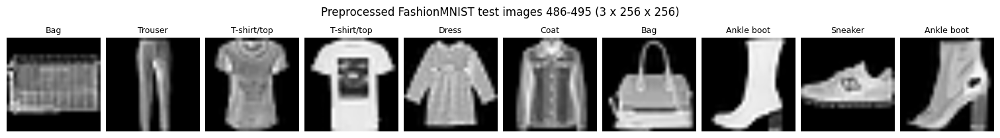

In [11]:
show_ids = list(range(SLICE, SLICE + 10))
fig, axes = plt.subplots(1, 10, figsize=(15, 2.2))
for ax, i in zip(axes, show_ids):
    img, lab = test_set[i]
    ax.imshow(denorm(img).permute(1, 2, 0).numpy())
    ax.set_title(class_names[lab], fontsize=9)
    ax.axis("off")
fig.suptitle(f"Preprocessed FashionMNIST test images {SLICE}-{SLICE + 9} (3 x {IMG_SIZE} x {IMG_SIZE})")
plt.savefig("figures/fashionmnist_examples.png", dpi=120)
plt.show()

## 6. Loading the Pretrained VAE (Assignment Part 1)

`AutoencoderKL` from `diffusers` is the VAE used by Stable Diffusion, and `sd-vae-ft-mse` is the version whose decoder was fine-tuned with an MSE loss, so it gives smoother reconstructions. It's a public model, so no Hugging Face login is needed (Colab may print a warning about a missing `HF_TOKEN`, which can be ignored).

The VAE is only used, never trained, so all its parameters are frozen (like in the demo). I wrote two small helpers so the scaling is always done the same way:

- `vae_encode_dist(x)` returns the mean and standard deviation of q(z | x). A latent sample is `(mean + std·ε) · 0.18215`, which is the demo's `latent_dist.sample() * 0.18215`.
- `vae_decode(z)` takes a **scaled** latent, divides by 0.18215 first (the demo's `vae.decode(latents / 0.18215)`), and returns an image in roughly [-1, 1].

In [12]:
t0 = time.time()
vae = AutoencoderKL.from_pretrained(VAE_NAME).to(device).eval()
vae.requires_grad_(False)
vae_params = sum(p.numel() for p in vae.parameters())
log(f"VAE {VAE_NAME} loaded in {time.time() - t0:.1f}s | {vae_params:,} parameters (frozen) | "
    f"latent channels {vae.config.latent_channels} | config scaling_factor {vae.config.scaling_factor}")


@torch.no_grad()
def vae_encode_dist(x):
    # x: [B, 3, H, W] in [-1, 1] -> mean and std of q(z|x), both [B, 4, H/8, W/8], unscaled
    with autocast():
        dist = vae.encode(x).latent_dist
    return dist.mean.float(), dist.std.float()


@torch.no_grad()
def vae_decode(z_scaled):
    # z_scaled: latent multiplied by LATENT_SCALE -> image [B, 3, H, W]
    with autocast():
        img = vae.decode(z_scaled / LATENT_SCALE).sample
    return img.float()


@torch.no_grad()
def decode_in_batches(z_scaled):
    return torch.cat([vae_decode(z_scaled[i:i + VAE_BATCH].to(device)).cpu() for i in range(0, len(z_scaled), VAE_BATCH)])

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_validators.py:206: UserWarning: The `local_dir_use_symlinks` argument is deprecated and ignored in `hf_hub_download`. Downloading to a local directory does not use symlinks anymore.
  warnings.warn(


config.json:   0%|          | 0.00/547 [00:00<?, ?B/s]

diffusion_pytorch_model.safetensors: reconstructing file:   0%|          |  0.00B /  335MB            

diffusion_pytorch_model.safetensors: downloading bytes:           |  0.00B            

[2026-11-03T20:18:05Z] VAE stabilityai/sd-vae-ft-mse loaded in 5.7s | 83,653,863 parameters (frozen) | latent channels 4 | config scaling_factor 0.18215


Encode and decode one image the same way as the demo (`latent_dist.sample() * 0.18215`, then `vae.decode(latents / 0.18215)`), to check the shapes:

In [13]:
x = preprocess(test_set.data[SLICE:SLICE + 1])
with torch.no_grad(), autocast():
    latent_dist = vae.encode(x).latent_dist
    latents = latent_dist.sample(generator=make_generator(SEED)).float() * LATENT_SCALE
recon = vae_decode(latents)

image_numbers = x[0].numel()
latent_numbers = latents[0].numel()
log(f"image shape {tuple(x.shape)} -> latent shape {tuple(latents.shape)} -> reconstruction shape {tuple(recon.shape)}")
log(f"numbers per image {image_numbers:,} vs per latent {latent_numbers:,} -> {image_numbers / latent_numbers:.0f}x smaller "
    f"(the original 28x28 FashionMNIST image has {28 * 28} pixels)")
assert latents.shape == (1, 4, IMG_SIZE // 8, IMG_SIZE // 8) and recon.shape == x.shape
LATENT_SHAPE = tuple(latents.shape[1:])

[2026-11-03T20:18:10Z] image shape (1, 3, 256, 256) -> latent shape (1, 4, 32, 32) -> reconstruction shape (1, 3, 256, 256)
[2026-11-03T20:18:10Z] numbers per image 196,608 vs per latent 4,096 -> 48x smaller (the original 28x28 FashionMNIST image has 784 pixels)


## 7. VAE Reconstruction and MSE

To check how much the compression loses, I encode the N_RECON = 1000 test images starting at index SLICE, decode them again, and measure the mean squared error against the preprocessed input. Both are in [-1, 1], and the MSE is averaged over all 3 × 256 × 256 values of each image. (Dividing by 4 gives the MSE on the [0, 1] scale.)

I report two versions:

- **sampled latent:** `z = (mean + std·ε) · s`, which is exactly what the diffusion model is trained on,
- **mean latent:** `z = mean · s`, which removes the small sampling noise from the encoder.

The decoded output is clamped to [-1, 1] first, because that's the valid image range.

In [14]:
recon_ids = torch.arange(SLICE, SLICE + N_RECON)
gen_recon = make_generator(SEED)
mse_sampled, mse_mean, recon_examples = [], [], None

t0 = time.time()
for i in range(0, N_RECON, VAE_BATCH):
    ids = recon_ids[i:i + VAE_BATCH]
    xb = preprocess(test_set.data[ids])
    mean, std = vae_encode_dist(xb)
    z_sampled = (mean + std * randn(mean.shape, gen_recon)) * LATENT_SCALE
    rec_s = vae_decode(z_sampled).clamp(-1, 1)
    rec_m = vae_decode(mean * LATENT_SCALE).clamp(-1, 1)
    mse_sampled.append(((rec_s - xb) ** 2).mean(dim=(1, 2, 3)).cpu())
    mse_mean.append(((rec_m - xb) ** 2).mean(dim=(1, 2, 3)).cpu())
    if recon_examples is None:
        recon_examples = (xb[:8].cpu(), rec_s[:8].cpu())
sync()
recon_time = time.time() - t0

mse_sampled = torch.cat(mse_sampled)
mse_mean = torch.cat(mse_mean)
recon_labels = test_set.targets[recon_ids]
recon_mse = {
    "n_images": N_RECON,
    "mse_sampled_latent": mse_sampled.mean().item(),
    "mse_mean_latent": mse_mean.mean().item(),
    "mse_sampled_latent_01_scale": mse_sampled.mean().item() / 4,
    "per_class_mse_sampled": {class_names[c]: mse_sampled[recon_labels == c].mean().item()
                              for c in range(NUM_CLASSES) if (recon_labels == c).any()},
}
log(f"reconstruction on {N_RECON} test images ({recon_time:.1f}s): MSE sampled latent {recon_mse['mse_sampled_latent']:.5f} | "
    f"mean latent {recon_mse['mse_mean_latent']:.5f} | sampled on [0,1] scale {recon_mse['mse_sampled_latent_01_scale']:.5f}")
print(f"{'class':<12} {'MSE':>9}")
for name, v in recon_mse["per_class_mse_sampled"].items():
    print(f"{name:<12} {v:>9.5f}")

[2026-11-03T20:21:59Z] reconstruction on 1000 test images (229.4s): MSE sampled latent 0.00013 | mean latent 0.00013 | sampled on [0,1] scale 0.00003
class              MSE
T-shirt/top    0.00012
Trouser        0.00013
Pullover       0.00013
Dress          0.00013
Coat           0.00012
Sandal         0.00014
Shirt          0.00014
Sneaker        0.00013
Bag            0.00015
Ankle boot     0.00012


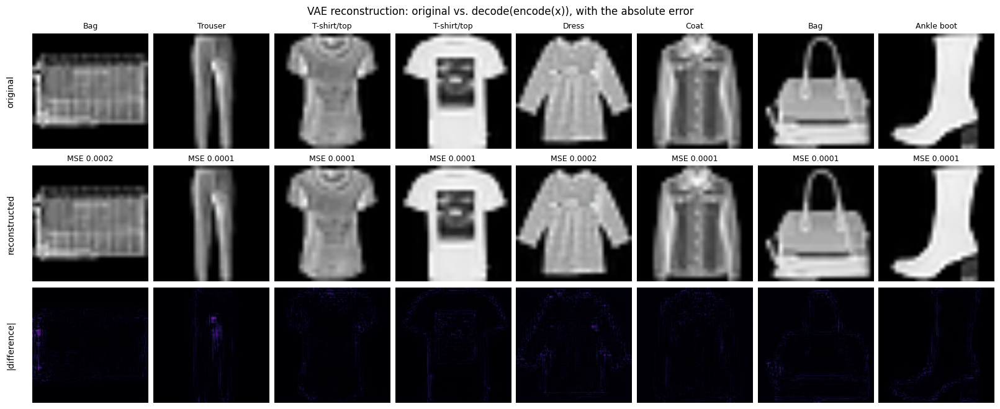

In [15]:
orig, rec = recon_examples
fig, axes = plt.subplots(3, 8, figsize=(16, 6.5))
for j in range(8):
    diff = (rec[j] - orig[j]).abs().mean(0)
    axes[0, j].imshow(denorm(orig[j]).permute(1, 2, 0).numpy())
    axes[0, j].set_title(class_names[recon_labels[j]], fontsize=9)
    axes[1, j].imshow(denorm(rec[j]).permute(1, 2, 0).numpy())
    axes[1, j].set_title(f"MSE {mse_sampled[j]:.4f}", fontsize=9)
    axes[2, j].imshow(diff.numpy(), cmap="magma", vmin=0, vmax=0.5)
    for i in range(3):
        axes[i, j].axis("off")
axes[0, 0].text(-0.15, 0.5, "original", transform=axes[0, 0].transAxes, rotation=90, va="center", ha="right")
axes[1, 0].text(-0.15, 0.5, "reconstructed", transform=axes[1, 0].transAxes, rotation=90, va="center", ha="right")
axes[2, 0].text(-0.15, 0.5, "|difference|", transform=axes[2, 0].transAxes, rotation=90, va="center", ha="right")
fig.suptitle("VAE reconstruction: original vs. decode(encode(x)), with the absolute error")
plt.savefig("figures/vae_reconstructions.png", dpi=120)
plt.show()

> **Observation:** The VAE loses very little here. Over 1,000 test images the reconstruction MSE is 0.00013 on the [-1, 1] scale (0.00003 on [0, 1]). Sampled and mean latents give practically the same number because the encoder's std is tiny (about 0.00003 after scaling), so the sampling noise hardly matters. Bag has the highest per-class MSE (0.000146) and Coat the lowest (0.000122). In the figure I can't tell the reconstructions from the originals by eye, and the difference maps only show faint lines around edges. One thing to keep in mind is that these images are upscaled from 28×28, so they are smooth and probably easier to reconstruct than real photos.

## 8. Looking at the Latent Representation

The latent for one 3 × 256 × 256 image is 4 × 32 × 32 = 4,096 numbers instead of 196,608, so it's 48 times smaller than the VAE input. It's not smaller than the original 28 × 28 FashionMNIST image (784 pixels), though. The compression is relative to the 256 × 256 RGB image the VAE sees, and the reason for resizing is to make the image fit the VAE (and the 16×16 attention), not to save space compared with raw FashionMNIST.

The plot shows the 4 latent channels of the image from Section 6. The 0.18215 factor is meant to give the latents roughly unit variance for Stable Diffusion's training images. FashionMNIST is very different from those images (mostly flat black background), so I print the actual mean and standard deviation of the scaled latents for the reconstruction set to see how close to 1 they are. The diffusion noise ε has variance 1, so this tells us how the signal and the noise compare in size.

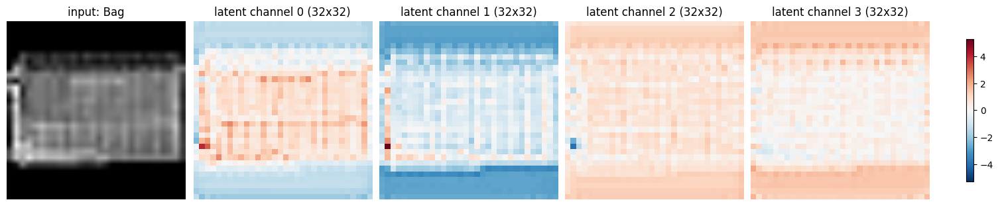

[2026-11-03T20:22:05Z] scaled latents (64 test images): mean 0.0048, std 1.3460 | per-channel std [1.244, 1.412, 0.506, 0.784] | average encoder std (scaled) 0.00003


In [16]:
fig, axes = plt.subplots(1, 5, figsize=(15, 3))
axes[0].imshow(denorm(x[0]).permute(1, 2, 0).cpu().numpy())
axes[0].set_title(f"input: {class_names[label]}")
axes[0].axis("off")
lim = latents.abs().max().item()
for c in range(4):
    im = axes[c + 1].imshow(latents[0, c].cpu().numpy(), cmap="RdBu_r", vmin=-lim, vmax=lim)
    axes[c + 1].set_title(f"latent channel {c} (32x32)")
    axes[c + 1].axis("off")
fig.colorbar(im, ax=axes[1:], shrink=0.8)
plt.savefig("figures/latent_channels.png", dpi=120)
plt.show()

# statistics of scaled latents over a batch of test images
xb = preprocess(test_set.data[recon_ids[:VAE_BATCH]])
mean_b, std_b = vae_encode_dist(xb)
z_b = mean_b * LATENT_SCALE
latent_stats = {
    "scaled_mean": z_b.mean().item(),
    "scaled_std": z_b.std().item(),
    "per_channel_std": [z_b[:, c].std().item() for c in range(4)],
    "per_channel_mean": [z_b[:, c].mean().item() for c in range(4)],
    "encoder_std_mean_scaled": (std_b * LATENT_SCALE).mean().item(),
}
log(f"scaled latents ({len(xb)} test images): mean {latent_stats['scaled_mean']:.4f}, std {latent_stats['scaled_std']:.4f} | "
    f"per-channel std {[round(v, 3) for v in latent_stats['per_channel_std']]} | "
    f"average encoder std (scaled) {latent_stats['encoder_std_mean_scaled']:.5f}")

## 9. Forward Diffusion Schedule (Assignment Part 2)

Same as the CFG demo: T = 1000 steps with β_t going linearly from 1e-4 to 0.02.

$$\alpha_t = 1 - \beta_t, \qquad \bar{\alpha}_t = \prod_{i=1}^{t} \alpha_i$$

- **β_t** is the variance of the noise added at step t. It starts tiny and grows.
- **ᾱ_t** is how much of the original signal (in variance) is left after t steps. √ᾱ_t multiplies the clean latent and √(1 − ᾱ_t) multiplies the noise.

**Timestep convention.** In the formulas t goes from 1 to T, and t = 0 means the clean latent (ᾱ_0 = 1). Python arrays start at 0, so `betas[t - 1]` is β_t and the model receives the index `t - 1` in [0, 999], which is also what the demo's training loop uses (`torch.randint(0, 1000)`). The demo's forward-diffusion plot starts at t = 1, so it never shows the clean image; mine includes t = 0.

    t    beta_t  alpha_bar_t  sqrt(ab_t)  sqrt(1-ab_t)
    1   0.00010     0.999900      0.9999        0.0100
  200   0.00406     0.659039      0.8118        0.5839
  500   0.01004     0.078587      0.2803        0.9599
  800   0.01602     0.001532      0.0391        0.9992
 1000   0.02000     0.000040      0.0064        1.0000


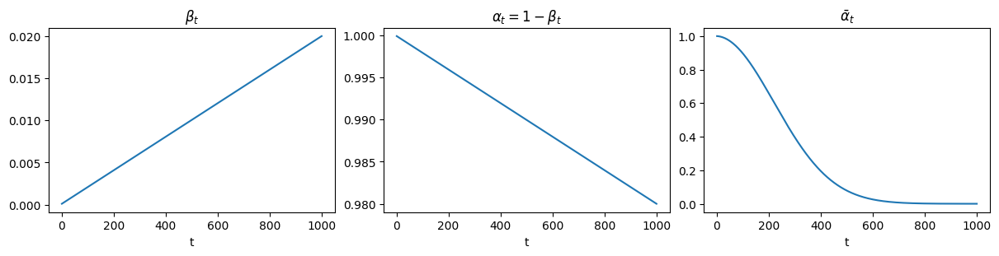

In [17]:
betas = torch.linspace(BETA_START, BETA_END, T, device=device)   # betas[t-1] = beta_t
alphas = 1 - betas
alpha_bars = torch.cumprod(alphas, dim=0)
sqrt_alpha_bars = torch.sqrt(alpha_bars)
sqrt_one_minus_alpha_bars = torch.sqrt(1 - alpha_bars)
alpha_bars_prev = F.pad(alpha_bars, (1, 0), value=1)[:-1]         # alpha_bar_{t-1}, with alpha_bar_0 = 1
posterior_sigma = torch.sqrt(betas * (1 - alpha_bars_prev) / (1 - alpha_bars))

assert betas.shape == alphas.shape == alpha_bars.shape == (T,)
assert abs(betas[0].item() - BETA_START) < 1e-9 and abs(betas[-1].item() - BETA_END) < 1e-9

schedule_table = {}
print(f"{'t':>5} {'beta_t':>9} {'alpha_bar_t':>12} {'sqrt(ab_t)':>11} {'sqrt(1-ab_t)':>13}")
for t in [1, 200, 500, 800, 1000]:
    ab = alpha_bars[t - 1].item()
    schedule_table[t] = ab
    print(f"{t:>5} {betas[t - 1].item():>9.5f} {ab:>12.6f} {math.sqrt(ab):>11.4f} {math.sqrt(1 - ab):>13.4f}")

plt.figure(figsize=(12, 3))
plt.subplot(1, 3, 1)
plt.plot(np.arange(1, T + 1), betas.cpu().numpy())
plt.title(r"$\beta_t$")
plt.xlabel("t")
plt.subplot(1, 3, 2)
plt.plot(np.arange(1, T + 1), alphas.cpu().numpy())
plt.title(r"$\alpha_t = 1-\beta_t$")
plt.xlabel("t")
plt.subplot(1, 3, 3)
plt.plot(np.arange(1, T + 1), alpha_bars.cpu().numpy())
plt.title(r"$\bar{\alpha}_t$")
plt.xlabel("t")
plt.savefig("figures/beta_schedule.png", dpi=120)
plt.show()

## 10. Noise Injection in Latent Space and Decoded Visualizations

The forward process from the assignment,

$$q(z_t \mid z_0) = \mathcal{N}\big(z_t;\ \sqrt{\bar\alpha_t}\, z_0,\ (1-\bar\alpha_t)\mathbf{I}\big),$$

can be sampled in one step with the reparameterization

$$z_t = \sqrt{\bar\alpha_t}\, z_0 + \sqrt{1-\bar\alpha_t}\, \epsilon, \qquad \epsilon \sim \mathcal{N}(0, \mathbf{I}).$$

`q_sample` is the demo's function. `z0` is the scaled VAE latent, `t` is the 0-based index, and the function returns both z_t and the noise ε, because ε is the training target. The check below draws many noise samples for one latent and confirms that z_t has mean √ᾱ_t·z_0 and variance 1 − ᾱ_t.

In [18]:
def q_sample(z0, t, noise=None):
    # z0: scaled latent [B, 4, 32, 32], t: 0-based timestep index [B]
    if noise is None:
        noise = torch.randn_like(z0)

    sqrt_ab = sqrt_alpha_bars[t].view(-1, 1, 1, 1)
    sqrt_1mab = sqrt_one_minus_alpha_bars[t].view(-1, 1, 1, 1)

    zt = sqrt_ab * z0 + sqrt_1mab * noise
    return zt, noise


# check the mean and variance of q(z_t | z_0) with many noise draws for one latent
z0_check = latents.expand(2000, -1, -1, -1)
for t in [200, 800]:
    idx = torch.full((2000,), t - 1, device=device, dtype=torch.long)
    zt, _ = q_sample(z0_check, idx, randn(z0_check.shape, make_generator(SEED)))
    mean_err = (zt.mean(0) - sqrt_alpha_bars[t - 1] * latents[0]).abs().max().item()
    var_emp = zt.var(0).mean().item()
    log(f"q_sample check t={t}: max |empirical mean - sqrt(ab) z0| = {mean_err:.4f}, "
        f"empirical variance {var_emp:.4f} vs 1 - alpha_bar = {1 - alpha_bars[t - 1].item():.4f}")
    assert abs(var_emp - (1 - alpha_bars[t - 1].item())) < 0.02

[2026-11-03T20:22:06Z] q_sample check t=200: max |empirical mean - sqrt(ab) z0| = 0.0519, empirical variance 0.3408 vs 1 - alpha_bar = 0.3410
[2026-11-03T20:22:06Z] q_sample check t=800: max |empirical mean - sqrt(ab) z0| = 0.0888, empirical variance 0.9980 vs 1 - alpha_bar = 0.9985


Now the required figure: the latent of one Shirt image (the first test image of class CLS_A = 6 at index SLICE or later) is noised to t ∈ {0, 200, 500, 800, 1000} with **one fixed ε**, and every z_t is decoded with `vae.decode(z_t / 0.18215)`.

To show the difference between **latent-space** and **pixel-space** diffusion, the second row applies the same formula with the same ᾱ_t directly to the 3 × 256 × 256 image, which is what the CFG demo does on 64×64 images. The third row shows latent channel 0 of z_t.

In pixel-space diffusion, the noise is added to every pixel independently, so the image looks like the picture plus "TV static". In latent-space diffusion the noise is added to the 4 × 32 × 32 latent, and the decoder turns that noise into structured artifacts (blobs and textures that the decoder knows how to draw), not per-pixel static. The decoder was never trained on very noisy latents, so at large t the decoded image is not a meaningful picture at all; it only shows what the decoder makes of a random latent.

[2026-11-03T20:22:07Z] forward diffusion image: test index 512 (Shirt)
[2026-11-03T20:22:07Z] MSE of decode(z_t) vs decode(z_0): t=0: 0.0000, t=200: 0.0662, t=500: 0.5357, t=800: 0.8400, t=1000: 0.8840


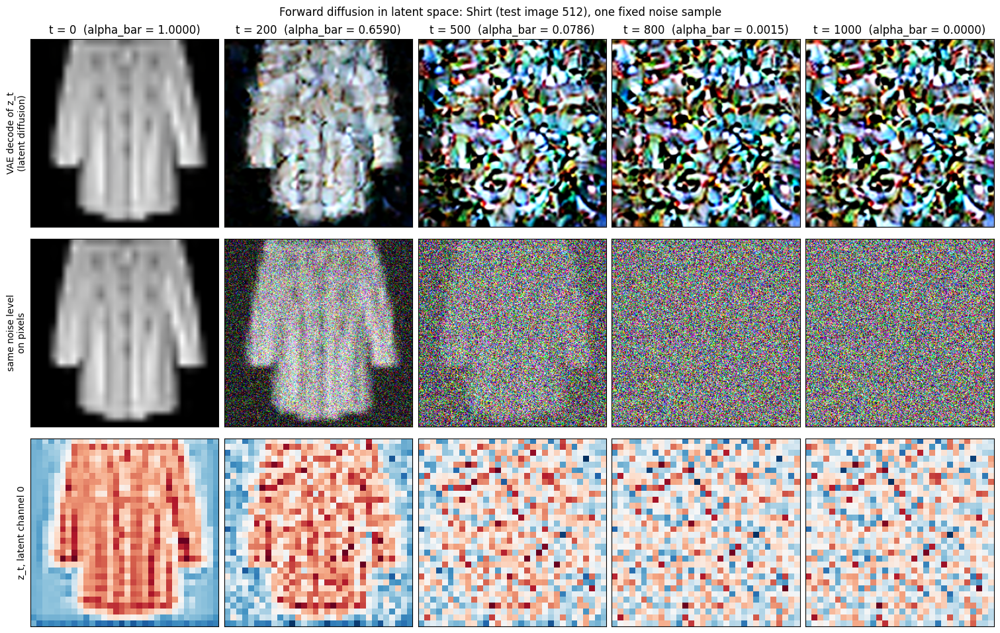

In [19]:
viz_idx = next(i for i in range(SLICE, len(test_set)) if test_set.targets[i] == CLS_A)
x_viz = preprocess(test_set.data[viz_idx:viz_idx + 1])
mean_v, std_v = vae_encode_dist(x_viz)
g_viz = make_generator(SEED)
z0_viz = (mean_v + std_v * randn(mean_v.shape, g_viz)) * LATENT_SCALE
eps_latent = randn(z0_viz.shape, g_viz)
eps_pixel = randn(x_viz.shape, g_viz)

viz_timesteps = [0, 200, 500, 800, 1000]
decoded_rows, pixel_rows, latent_rows, decoded_mse = [], [], [], {}
clean_decode = vae_decode(z0_viz)
for t in viz_timesteps:
    if t == 0:
        zt, xt = z0_viz, x_viz
    else:
        idx = torch.tensor([t - 1], device=device)
        zt, _ = q_sample(z0_viz, idx, eps_latent)
        xt, _ = q_sample(x_viz, idx, eps_pixel)
    dec = vae_decode(zt)
    decoded_mse[t] = ((dec.clamp(-1, 1) - clean_decode.clamp(-1, 1)) ** 2).mean().item()
    decoded_rows.append(dec[0].cpu())
    pixel_rows.append(xt[0].cpu())
    latent_rows.append(zt[0, 0].cpu())

log(f"forward diffusion image: test index {viz_idx} ({class_names[CLS_A]})")
log("MSE of decode(z_t) vs decode(z_0): " + ", ".join(f"t={t}: {v:.4f}" for t, v in decoded_mse.items()))

fig, axes = plt.subplots(3, len(viz_timesteps), figsize=(15, 9.5))
for j, t in enumerate(viz_timesteps):
    ab = 1.0 if t == 0 else alpha_bars[t - 1].item()
    axes[0, j].imshow(denorm(decoded_rows[j]).permute(1, 2, 0).numpy())
    axes[0, j].set_title(f"t = {t}  (alpha_bar = {ab:.4f})")
    axes[1, j].imshow(denorm(pixel_rows[j]).permute(1, 2, 0).numpy())
    axes[2, j].imshow(latent_rows[j].numpy(), cmap="RdBu_r", vmin=-3, vmax=3)
    for i in range(3):
        axes[i, j].set_xticks([])
        axes[i, j].set_yticks([])
axes[0, 0].set_ylabel("VAE decode of z_t\n(latent diffusion)")
axes[1, 0].set_ylabel("same noise level\non pixels")
axes[2, 0].set_ylabel("z_t, latent channel 0")
fig.suptitle(f"Forward diffusion in latent space: {class_names[CLS_A]} (test image {viz_idx}), one fixed noise sample")
plt.savefig("figures/forward_diffusion_latent.png", dpi=120)
plt.show()

> **Observation:** At t = 200 (ᾱ = 0.659) the Shirt is still easy to recognize, but it has blotchy colored patches on it. By t = 500 (ᾱ = 0.079) the decoded image doesn't show the shirt anymore, and t = 800 and t = 1000 look almost the same as each other. The MSE against the clean decode goes 0.0662, 0.5357, 0.8400, 0.8840 for t = 200, 500, 800, 1000, so most of the damage happens before t = 500. The pixel-space row looks different: the noise is fine static, and a faint outline of the shirt is still there at t = 500. The latent noise decodes into colorful blobs instead, which makes sense because one latent value covers an 8×8 pixel patch and the decoder was never trained on inputs like this.

## 11. Conditional Latent U-Net (Assignment Part 3)

The building blocks are the CFG demo's, with the changes listed at the top of the notebook:

- **`TimeEmbedding`**: the demo's sinusoidal embedding of the timestep index (64 numbers: 32 sines and 32 cosines at different frequencies).
- **Time MLP**: `Linear(64, 256) → SiLU → Linear(256, 256)`, as in the demo. The 256-dimensional result is the combined conditioning vector.
- **Label embedding**: `nn.Embedding(11, 256)`, with rows 0-9 for the FashionMNIST classes and row 10 for the null label. It is added to the time embedding, so every block gets one vector that says both "how noisy" and "which class". If `y` is `None`, the model uses label 10, which is how the unconditional prediction is made.
- **`ResidualBlock`**: GroupNorm → SiLU → 3×3 conv, then the conditioning vector is projected to the channel count and added per channel, then GroupNorm → SiLU → 3×3 conv. Then the input comes back through the shortcut (a 1×1 conv if the channels change). The demo's version skipped the shortcut.
- **`SelfAttention`**: the demo's block. The feature map is flattened into H·W tokens, normalized with GroupNorm, passed through 4-head multi-head attention with a residual add, then a small feed-forward layer with another residual add. At 16×16 that is 256 tokens, so every position can look at every other position in the image, which convolutions can't do in one layer.
- **Encoder / decoder blocks**: residual block, then 2×2 max-pool (encoder), or bilinear upsample + 3×3 conv, concatenate the skip connection, then a residual block (decoder). Same as the demo.

Shapes for a 4 × 32 × 32 latent (channels = 64 × (1, 2, 4)):

| Stage | Output | Attention |
| --- | --- | --- |
| `init_conv` | 64 × 32 × 32 | |
| `e1` (skip s1, then pool) | 64 × 32 × 32 → 64 × 16 × 16 | |
| `e2` (skip s2, then pool) | 128 × 16 × 16 → 128 × 8 × 8 | **yes, 16×16** |
| `e3` (skip s3, then pool) | 256 × 8 × 8 → 256 × 4 × 4 | |
| `bottleneck` | 256 × 4 × 4 | **yes (ResBlock → attention → ResBlock)** |
| `d1` (up + s3) | 128 × 8 × 8 | |
| `d2` (up + s2) | 64 × 16 × 16 | **yes, 16×16** |
| `d3` (up + s1) | 64 × 32 × 32 | |
| `final_conv` | 4 × 32 × 32 = predicted noise | |

The demo applies its first attention after pooling and its second after `d1`, which is 16×16 for its 64×64 input. With a 32×32 latent, 16×16 is the output of `e2` and `d2`, so that's where the attention goes here. The output has the same shape as the input latent, because the model predicts the noise ε that was added to it.

In [20]:
# Sinusoidal Time Embedding (from Demo_9_CFG)
class TimeEmbedding(nn.Module):
    def __init__(self, dim: int):
        super().__init__()
        self.dim = dim

    def forward(self, t):
        half_dim = self.dim // 2
        embeddings = np.log(10000) / (half_dim - 1)
        embeddings = torch.exp(torch.arange(half_dim, device=t.device) * -embeddings)
        embeddings = t[:, None] * embeddings[None, :]
        embeddings = torch.cat((embeddings.sin(), embeddings.cos()), dim=-1)
        return embeddings


# Residual Block with GroupNorm and SiLU (demo block + the missing shortcut)
class ResidualBlock(nn.Module):
    def __init__(self, in_channels: int, out_channels: int, time_channels: int):
        super().__init__()

        self.norm1 = nn.GroupNorm(8, in_channels)
        self.conv1 = nn.Conv2d(in_channels, out_channels, 3, padding=1)

        self.time_proj = nn.Linear(time_channels, out_channels)

        self.norm2 = nn.GroupNorm(8, out_channels)
        self.conv2 = nn.Conv2d(out_channels, out_channels, 3, padding=1)

        self.act = nn.SiLU()
        self.shortcut = nn.Conv2d(in_channels, out_channels, 1) if in_channels != out_channels else nn.Identity()

    def forward(self, x, t_emb):
        h = self.conv1(self.act(self.norm1(x)))

        time_emb_proj = self.time_proj(self.act(t_emb))[:, :, None, None]
        h = h + time_emb_proj

        h = self.conv2(self.act(self.norm2(h)))
        return h + self.shortcut(x)


# Self-attention (from Demo_9_CFG)
class SelfAttention(nn.Module):
    def __init__(self, channels: int):
        super().__init__()
        self.mha = nn.MultiheadAttention(channels, num_heads=4, batch_first=True)
        self.norm = nn.GroupNorm(8, num_channels=channels)

        self.ff = nn.Sequential(
            nn.LayerNorm(channels),
            nn.Linear(channels, channels),
            nn.SiLU(),
            nn.Linear(channels, channels),
        )

    def forward(self, x):
        b, c, h, w = x.shape

        x_flat = x.view(b, c, -1).permute(0, 2, 1)          # [B, H*W, C] tokens

        x_norm = self.norm(x_flat.permute(0, 2, 1)).permute(0, 2, 1)
        attn_out, _ = self.mha(x_norm, x_norm, x_norm, need_weights=False)
        x_flat = x_flat + attn_out

        x_flat = x_flat + self.ff(x_flat)

        return x_flat.permute(0, 2, 1).reshape(b, c, h, w)


# Bottleneck (from Demo_9_CFG)
class BottleNeck(nn.Module):
    def __init__(self, channels: int, time_channels: int):
        super().__init__()

        self.block1 = ResidualBlock(channels, channels, time_channels)
        self.attn = SelfAttention(channels)
        self.block2 = ResidualBlock(channels, channels, time_channels)

    def forward(self, x, t_emb):
        x = self.block1(x, t_emb)
        x = self.attn(x)
        x = self.block2(x, t_emb)
        return x


class EncoderBlock(nn.Module):
    def __init__(self, input_channels: int, output_channels: int, time_channels: int, attention: bool = False):
        super().__init__()
        self.block = ResidualBlock(input_channels, output_channels, time_channels)
        self.attn = SelfAttention(output_channels) if attention else nn.Identity()
        self.pool = nn.MaxPool2d((2, 2))

    def forward(self, x, t_emb):
        x = self.block(x, t_emb)
        x = self.attn(x)
        p = self.pool(x)
        return x, p  # return both for the skip connection


class DecoderBlock(nn.Module):
    def __init__(self, input_channels: int, output_channels: int, time_channels: int, attention: bool = False):
        super().__init__()
        self.up = nn.Sequential(
            nn.UpsamplingBilinear2d(scale_factor=2),
            nn.Conv2d(input_channels, input_channels, kernel_size=3, padding=1)
        )

        self.block = ResidualBlock(2 * input_channels, output_channels, time_channels)
        self.attn = SelfAttention(output_channels) if attention else nn.Identity()

    def forward(self, x, skip, t_emb):
        x = self.up(x)
        x = torch.cat([x, skip], dim=1)  # skip connection
        x = self.block(x, t_emb)
        x = self.attn(x)
        return x


class LatentUNet(nn.Module):
    def __init__(self, latent_channels: int = 4, base_channels: int = 64, channel_mults=(1, 2, 4), num_classes: int = 10):
        super().__init__()
        time_dim = base_channels * 4
        c1, c2, c3 = [base_channels * m for m in channel_mults]
        self.null_label = num_classes

        # Classifier-free guidance: 10 classes + 1 null label
        self.label_embedding = nn.Embedding(num_embeddings=num_classes + 1, embedding_dim=time_dim)

        # Time embedding + MLP
        self.time_mlp = nn.Sequential(
            TimeEmbedding(base_channels),
            nn.Linear(base_channels, time_dim),
            nn.SiLU(),
            nn.Linear(time_dim, time_dim),
        )

        self.init_conv = nn.Conv2d(latent_channels, c1, kernel_size=3, padding="same")

        self.e1 = EncoderBlock(c1, c1, time_dim)                  # 32x32
        self.e2 = EncoderBlock(c1, c2, time_dim, attention=True)  # 16x16 + attention
        self.e3 = EncoderBlock(c2, c3, time_dim)                  # 8x8

        self.bottleneck = BottleNeck(c3, time_dim)                # 4x4 + attention

        self.d1 = DecoderBlock(c3, c2, time_dim)                  # 8x8
        self.d2 = DecoderBlock(c2, c1, time_dim, attention=True)  # 16x16 + attention
        self.d3 = DecoderBlock(c1, c1, time_dim)                  # 32x32

        self.final_conv = nn.Conv2d(c1, latent_channels, kernel_size=1)

    def embed(self, t, y=None):
        if y is None:
            y = torch.full((t.shape[0],), self.null_label, device=t.device, dtype=torch.long)
        # combining the time and label embeddings
        return self.time_mlp(t) + self.label_embedding(y)

    def forward(self, x, t, y=None):
        t_emb = self.embed(t, y)

        x = self.init_conv(x)
        s1, p1 = self.e1(x, t_emb)
        s2, p2 = self.e2(p1, t_emb)
        s3, p3 = self.e3(p2, t_emb)

        b = self.bottleneck(p3, t_emb)

        x = self.d1(b, s3, t_emb)
        x = self.d2(x, s2, t_emb)
        x = self.d3(x, s1, t_emb)

        return self.final_conv(x)

## 12. Architecture and Tensor-Shape Checks

Before training, the checks below confirm that:

- the output has the same shape as the latent input (4 × 32 × 32),
- the time embedding and the label embedding are both [B, 256],
- self-attention really runs at 16×16 (in `e2` and `d2`) and at 4×4 in the bottleneck (checked with forward hooks),
- `y=None` gives exactly the same output as passing label 10, so the null label is what the unconditional prediction uses,
- different class labels give different outputs (the label actually reaches the network),
- a backward pass on a small batch gives gradients for every parameter.

In [21]:
set_seed(SEED)
model = LatentUNet(latent_channels=LATENT_SHAPE[0], base_channels=BASE_CHANNELS,
                   channel_mults=CHANNEL_MULTS, num_classes=NUM_CLASSES).to(device)
n_params = sum(p.numel() for p in model.parameters())
log(f"LatentUNet: {n_params:,} parameters")
for name in ["time_mlp", "label_embedding", "init_conv", "e1", "e2", "e3", "bottleneck", "d1", "d2", "d3", "final_conv"]:
    print(f"  {name:<16} {sum(p.numel() for p in getattr(model, name).parameters()):>10,}")

attn_sizes = {}
hooks = [m.register_forward_hook(lambda mod, inp, out, n=n: attn_sizes.__setitem__(n, tuple(inp[0].shape[1:])))
         for n, m in model.named_modules() if isinstance(m, SelfAttention)]

g_check = make_generator(SEED)
zc = randn((4, *LATENT_SHAPE), g_check)
tc = torch.tensor([0, 250, 500, 999], device=device)
yc = torch.tensor([0, 3, 6, 9], device=device)
with torch.no_grad():
    out = model(zc, tc, yc)
    t_emb_shape = tuple(model.time_mlp(tc).shape)
    y_emb_shape = tuple(model.label_embedding(yc).shape)
    out_none = model(zc, tc, None)
    out_null = model(zc, tc, torch.full_like(yc, NULL_LABEL))
    out_other = model(zc, tc, (yc + 1) % NUM_CLASSES)
for h in hooks:
    h.remove()

log(f"input {tuple(zc.shape)} -> output {tuple(out.shape)} | time embedding {t_emb_shape} | label embedding {y_emb_shape}")
log("self-attention input sizes (C, H, W): " + ", ".join(f"{n}: {s}" for n, s in attn_sizes.items()))
assert out.shape == zc.shape
assert t_emb_shape == y_emb_shape == (4, BASE_CHANNELS * 4)
assert attn_sizes["e2.attn"][1:] == (16, 16) and attn_sizes["d2.attn"][1:] == (16, 16)
assert attn_sizes["bottleneck.attn"][1:] == (4, 4)
assert torch.equal(out_none, out_null), "y=None should be the same as the null label"
assert not torch.allclose(out, out_other), "changing the label should change the output"

# small backward pass
loss_check = F.mse_loss(model(zc, tc, yc), randn(zc.shape, g_check))
loss_check.backward()
no_grad = [n for n, p in model.named_parameters() if p.grad is None or p.grad.abs().sum() == 0]
used_rows = model.label_embedding.weight.grad.abs().sum(1).nonzero().flatten().tolist()
log(f"backward check: loss {loss_check.item():.4f} | parameters without gradient: {no_grad} | label rows with gradient: {used_rows}")
assert not no_grad and used_rows == [0, 3, 6, 9]
model.zero_grad(set_to_none=True)

[2026-11-03T20:22:09Z] LatentUNet: 6,406,596 parameters
  time_mlp             82,432
  label_embedding       2,816
  init_conv             2,368
  e1                   90,560
  e2                  362,624
  e3                  984,832
  bottleneck        2,889,728
  d1                1,427,456
  d2                  390,784
  d3                  172,736
  final_conv              260
[2026-11-03T20:22:09Z] input (4, 4, 32, 32) -> output (4, 4, 32, 32) | time embedding (4, 256) | label embedding (4, 256)
[2026-11-03T20:22:09Z] self-attention input sizes (C, H, W): e2.attn: (128, 16, 16), bottleneck.attn: (256, 4, 4), d2.attn: (64, 16, 16)
[2026-11-03T20:22:10Z] backward check: loss 1.0933 | parameters without gradient: [] | label rows with gradient: [0, 3, 6, 9]


/usr/local/lib/python3.13/dist-packages/torch/autograd/graph.py:869: UserWarning: Memory Efficient attention defaults to a non-deterministic algorithm. To explicitly enable determinism call torch.use_deterministic_algorithms(True, warn_only=False). (Triggered internally at /pytorch/aten/src/ATen/native/transformers/cuda/attention_backward.cu:900.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass


## 13. Training Setup (Assignment Part 4)

### Caching the VAE latents

The VAE encoder costs much more than the U-Net (roughly 270 GFLOPs per 256×256 image vs. about 1.2 GFLOPs for one U-Net forward pass), and it is frozen, so its output for a given image never changes. So I encode every training and test image **once** and store the mean and standard deviation of q(z | x) (unscaled, in float16 to save memory: 70,000 × 2 × 4 × 32 × 32 values is about 1.1 GB).

During training, `sample_z0` draws a new `z0 = (mean + std·ε) · 0.18215` each time an image is used, so the model sees a fresh latent sample like in the demo's loop, where `vae.encode(images).latent_dist.sample() * 0.18215` was called on every batch. The cache is saved to `cache/` (not part of the outputs) so a restarted runtime can reuse it.

In [22]:
def encode_split(dataset, ids, name):
    means = torch.empty((len(ids), *LATENT_SHAPE), dtype=torch.float16)
    stds = torch.empty((len(ids), *LATENT_SHAPE), dtype=torch.float16)
    t0 = time.time()
    n_batches = math.ceil(len(ids) / VAE_BATCH)
    for k, i in enumerate(range(0, len(ids), VAE_BATCH)):
        batch_ids = ids[i:i + VAE_BATCH]
        mean, std = vae_encode_dist(preprocess(dataset.data[batch_ids]))
        assert torch.isfinite(mean).all() and torch.isfinite(std).all()
        means[i:i + len(batch_ids)] = mean.half().cpu()
        stds[i:i + len(batch_ids)] = std.half().cpu()
        if (k + 1) % max(1, n_batches // 10) == 0 or k + 1 == n_batches:
            elapsed = time.time() - t0
            log(f"  encoding {name}: {i + len(batch_ids):,}/{len(ids):,} images | {elapsed:.0f}s | "
                f"ETA {elapsed / (k + 1) * (n_batches - k - 1):.0f}s")
    return means, stds


cache_name = f"fmnist_latents_{IMG_SIZE}_{len(train_ids)}_{len(test_ids)}.pt"
cache_path = os.path.join("cache", cache_name)
if not os.path.exists(cache_path) and BACKUP_DIR and os.path.exists(os.path.join(BACKUP_DIR, cache_name)):
    shutil.copy(os.path.join(BACKUP_DIR, cache_name), cache_path)
    log("copied the latent cache back from", BACKUP_DIR)

t0 = time.time()
if os.path.exists(cache_path):
    cache = torch.load(cache_path)
    log(f"loaded latent cache {cache_path}")
else:
    cache = {}
    cache["train_mean"], cache["train_std"] = encode_split(train_set, train_ids, "train")
    cache["test_mean"], cache["test_std"] = encode_split(test_set, test_ids, "test")
    torch.save(cache, cache_path)
    if BACKUP_DIR:
        os.makedirs(BACKUP_DIR, exist_ok=True)
        shutil.copy(cache_path, os.path.join(BACKUP_DIR, cache_name))
cache_time = time.time() - t0

train_mean, train_std = cache["train_mean"].to(device), cache["train_std"].to(device)
test_mean, test_std = cache["test_mean"].to(device), cache["test_std"].to(device)
train_y, test_y = train_labels.to(device), test_labels.to(device)
assert train_mean.shape == (len(train_ids), *LATENT_SHAPE) and test_mean.shape == (len(test_ids), *LATENT_SHAPE)

# the cached mean for image SLICE should match encoding it again
check_mean, _ = vae_encode_dist(preprocess(test_set.data[SLICE:SLICE + 1]))
if SLICE < len(test_ids):
    cache_err = (check_mean[0].half() - test_mean[SLICE]).abs().max().item()
    log(f"cache check: max difference for test image {SLICE} = {cache_err:.5f}")

train_scaled = train_mean.float() * LATENT_SCALE
log(f"latent cache ready in {cache_time:.0f}s | train {tuple(train_mean.shape)}, test {tuple(test_mean.shape)} | "
    f"scaled train latents: mean {train_scaled.mean().item():.4f}, std {train_scaled.std().item():.4f}")
latent_stats["train_scaled_mean"] = train_scaled.mean().item()
latent_stats["train_scaled_std"] = train_scaled.std().item()
del train_scaled

[2026-11-03T20:25:32Z]   encoding train: 5,952/60,000 images | 202s | ETA 1837s
[2026-11-03T20:28:54Z]   encoding train: 11,904/60,000 images | 404s | ETA 1632s
[2026-11-03T20:32:15Z]   encoding train: 17,856/60,000 images | 605s | ETA 1428s
[2026-11-03T20:35:36Z]   encoding train: 23,808/60,000 images | 806s | ETA 1226s
[2026-11-03T20:38:57Z]   encoding train: 29,760/60,000 images | 1007s | ETA 1024s
[2026-11-03T20:42:18Z]   encoding train: 35,712/60,000 images | 1208s | ETA 823s
[2026-11-03T20:45:39Z]   encoding train: 41,664/60,000 images | 1409s | ETA 621s
[2026-11-03T20:49:01Z]   encoding train: 47,616/60,000 images | 1611s | ETA 420s
[2026-11-03T20:52:22Z]   encoding train: 53,568/60,000 images | 1812s | ETA 219s
[2026-11-03T20:55:43Z]   encoding train: 59,520/60,000 images | 2013s | ETA 17s
[2026-11-03T20:55:59Z]   encoding train: 60,000/60,000 images | 2029s | ETA 0s
[2026-11-03T20:56:32Z]   encoding test: 960/10,000 images | 32s | ETA 307s
[2026-11-03T20:57:04Z]   encoding tes

### Loss, label dropout, and checkpoints

For each batch (as in the demo):

1. draw a clean latent sample z_0 for every image (from the cache),
2. with probability 0.1 drop the labels for the **whole batch** (`y = None`, so the model uses the null label 10), like the demo's `if torch.rand(1) < drop_label_probability`,
3. draw a random timestep index t in [0, 999] and noise ε for each image,
4. make z_t with `q_sample`, predict ε̂ = ε_θ(z_t, t, y), and use the MSE between ε̂ and ε as the loss.

The optimizer is Adam with lr 2e-5, as in the demo. With micro-batches, each micro-batch loss is weighted by its share of the batch before `backward()`, so the summed gradient is the gradient of the full-batch mean loss.

The **test loss** uses the same steps on the test latents (including the label dropout, like the demo), but the generator is reset to the same seed every epoch, so every epoch is scored on exactly the same timesteps, noise, and dropped batches.

A checkpoint (model, optimizer, scaler, losses, random generator state) is saved after every epoch to `checkpoints/ldm_unet_latest.pt`. If the runtime restarts, rerunning the notebook continues from the last finished epoch, as long as the settings are the same.

In [23]:
optimizer = optim.Adam(model.parameters(), lr=LR)
scaler = torch.amp.GradScaler("cuda", enabled=USE_AMP)


def sample_z0(mean_bank, std_bank, ids, gen):
    mean = mean_bank[ids].float()
    std = std_bank[ids].float()
    return (mean + std * randn(mean.shape, gen)) * LATENT_SCALE


def diffusion_loss(mean_bank, std_bank, label_bank, ids, drop_labels, gen):
    z0 = sample_z0(mean_bank, std_bank, ids, gen)
    y = None if drop_labels else label_bank[ids]
    t = torch.randint(0, T, (len(ids),), generator=gen).to(device)
    z_t, noise_target = q_sample(z0, t, randn(z0.shape, gen))
    with autocast():
        noise_pred = model(z_t, t, y)
    return F.mse_loss(noise_pred.float(), noise_target)


@torch.no_grad()
def evaluate(mean_bank, std_bank, label_bank, mode="demo", seed=SEED + 1):
    # mode "demo": drop labels per batch with p = 0.1 (same as training), "cond": never drop, "uncond": always drop
    model.eval()
    gen = make_generator(seed)
    n = len(label_bank)
    total = 0.0
    n_batches = 0
    for b in range(0, n, BATCH_SIZE):
        ids = torch.arange(b, min(b + BATCH_SIZE, n), device=device)
        drop = torch.rand(1, generator=gen).item() < DROP_LABEL_PROB
        drop = {"demo": drop, "cond": False, "uncond": True}[mode]
        batch_loss = 0.0
        for m in range(0, len(ids), MICRO_BATCH):
            mids = ids[m:m + MICRO_BATCH]
            batch_loss += diffusion_loss(mean_bank, std_bank, label_bank, mids, drop, gen).item() * len(mids) / len(ids)
        total += batch_loss
        n_batches += 1
    return total / n_batches


CKPT_LATEST = "checkpoints/ldm_unet_latest.pt"


def save_checkpoint(epoch, gen):
    torch.save({
        "epoch": epoch, "config": CONFIG, "model": model.state_dict(), "optimizer": optimizer.state_dict(),
        "scaler": scaler.state_dict(), "training_losses": training_losses, "testing_losses": testing_losses,
        "epoch_times": epoch_times, "initial_test_loss": initial_test_loss, "generator": gen.get_state(),
    }, CKPT_LATEST)
    if BACKUP_DIR:
        os.makedirs(BACKUP_DIR, exist_ok=True)
        shutil.copy(CKPT_LATEST, os.path.join(BACKUP_DIR, os.path.basename(CKPT_LATEST)))


print(f"batches per epoch: train {math.ceil(len(train_ids) / BATCH_SIZE)}, test {math.ceil(len(test_ids) / BATCH_SIZE)} | "
      f"micro-batches per batch: {math.ceil(BATCH_SIZE / MICRO_BATCH)} | total optimizer steps: {EPOCHS * math.ceil(len(train_ids) / BATCH_SIZE)}")

batches per epoch: train 60, test 10 | micro-batches per batch: 4 | total optimizer steps: 3000


## 14. Training Loop

This is the demo's loop on cached latents. Each epoch logs the mean training loss, the test loss, the time, and an estimate of the time left. The test loss before any training is also logged as a reference point (an untrained network predicting ε should give an MSE of about 1 or more, since ε has variance 1).

In [24]:
training_losses, testing_losses, epoch_times = [], [], []
initial_test_loss = None
start_epoch = 0
g_train = make_generator(SEED)

backup_ckpt = os.path.join(BACKUP_DIR, os.path.basename(CKPT_LATEST)) if BACKUP_DIR else None
if RESUME and not os.path.exists(CKPT_LATEST) and backup_ckpt and os.path.exists(backup_ckpt):
    shutil.copy(backup_ckpt, CKPT_LATEST)
if RESUME and os.path.exists(CKPT_LATEST):
    ckpt = torch.load(CKPT_LATEST, map_location=device, weights_only=False)
    if ckpt["config"] == CONFIG:
        model.load_state_dict(ckpt["model"])
        optimizer.load_state_dict(ckpt["optimizer"])
        scaler.load_state_dict(ckpt["scaler"])
        training_losses, testing_losses = ckpt["training_losses"], ckpt["testing_losses"]
        epoch_times, initial_test_loss = ckpt["epoch_times"], ckpt["initial_test_loss"]
        g_train.set_state(ckpt["generator"])
        start_epoch = ckpt["epoch"]
        log(f"resumed from {CKPT_LATEST} after epoch {start_epoch}")
    else:
        log("found a checkpoint with different settings, starting from scratch")

if initial_test_loss is None:
    initial_test_loss = evaluate(test_mean, test_std, test_y)
    log(f"test loss before training: {initial_test_loss:.5f}")

n_train = len(train_ids)
train_start = time.time()
for epoch in range(start_epoch, EPOCHS):
    model.train()
    t0 = time.time()
    perm = torch.randperm(n_train, generator=g_train).to(device)
    epoch_training_loss = 0.0
    n_batches = 0

    for b in range(0, n_train, BATCH_SIZE):
        ids = perm[b:b + BATCH_SIZE]

        # Drop labels w/ probability (whole batch, as in the demo)
        drop = torch.rand(1, generator=g_train).item() < DROP_LABEL_PROB

        optimizer.zero_grad(set_to_none=True)
        batch_loss = 0.0
        for m in range(0, len(ids), MICRO_BATCH):
            mids = ids[m:m + MICRO_BATCH]
            loss = diffusion_loss(train_mean, train_std, train_y, mids, drop, g_train)
            weight = len(mids) / len(ids)
            scaler.scale(loss * weight).backward()
            batch_loss += loss.item() * weight
        scaler.step(optimizer)
        scaler.update()

        epoch_training_loss += batch_loss
        n_batches += 1

    training_losses.append(epoch_training_loss / n_batches)
    testing_losses.append(evaluate(test_mean, test_std, test_y))
    sync()
    epoch_times.append(time.time() - t0)
    save_checkpoint(epoch + 1, g_train)

    eta = np.mean(epoch_times[-5:]) * (EPOCHS - epoch - 1)
    log(f"epoch {epoch + 1:>2}/{EPOCHS} | train {training_losses[-1]:.5f} | test {testing_losses[-1]:.5f} | "
        f"{epoch_times[-1]:.1f}s | ETA {eta / 60:.1f} min")

train_time = sum(epoch_times)
log(f"training done | total training time {train_time:.1f}s ({train_time / 60:.1f} min) | "
    f"final train {training_losses[-1]:.5f} | final test {testing_losses[-1]:.5f}")
if device == "cuda":
    log(f"peak GPU memory: {torch.cuda.max_memory_allocated() / 1e9:.2f} GB")

[2026-11-03T21:01:43Z] test loss before training: 1.07267
[2026-11-03T21:03:18Z] epoch  1/50 | train 0.89949 | test 0.77814 | 94.4s | ETA 77.1 min
[2026-11-03T21:04:52Z] epoch  2/50 | train 0.64738 | test 0.52760 | 93.8s | ETA 75.3 min
[2026-11-03T21:06:26Z] epoch  3/50 | train 0.42929 | test 0.35180 | 94.0s | ETA 73.7 min
[2026-11-03T21:08:00Z] epoch  4/50 | train 0.29881 | test 0.26217 | 94.1s | ETA 72.1 min
[2026-11-03T21:09:34Z] epoch  5/50 | train 0.23921 | test 0.21878 | 93.8s | ETA 70.5 min
[2026-11-03T21:11:08Z] epoch  6/50 | train 0.20992 | test 0.20051 | 93.6s | ETA 68.8 min
[2026-11-03T21:12:42Z] epoch  7/50 | train 0.19529 | test 0.18857 | 93.9s | ETA 67.3 min
[2026-11-03T21:14:16Z] epoch  8/50 | train 0.18377 | test 0.17869 | 94.0s | ETA 65.7 min
[2026-11-03T21:15:50Z] epoch  9/50 | train 0.17562 | test 0.17102 | 93.8s | ETA 64.1 min
[2026-11-03T21:17:23Z] epoch 10/50 | train 0.16784 | test 0.16424 | 93.6s | ETA 62.5 min
[2026-11-03T21:18:57Z] epoch 11/50 | train 0.16133 |

## 15. Validation / Testing

The per-epoch test loss mixes conditional and unconditional batches (like the demo). After training I also score the whole test set two more ways, with the same timesteps and noise:

- **conditional**: every image gets its true label,
- **unconditional**: every image gets the null label.

If the label is useful to the model, the conditional loss should be a bit lower than the unconditional one, because knowing the class tells the model something about what the clean latent looks like.

In [25]:
final_test = {mode: evaluate(test_mean, test_std, test_y, mode=mode) for mode in ["demo", "cond", "uncond"]}
log(f"final test noise-prediction MSE | as during training: {final_test['demo']:.5f} | "
    f"conditional: {final_test['cond']:.5f} | unconditional (null label): {final_test['uncond']:.5f}")

[2026-11-03T22:20:19Z] final test noise-prediction MSE | as during training: 0.09184 | conditional: 0.09146 | unconditional (null label): 0.09345


## 16. Loss Curves

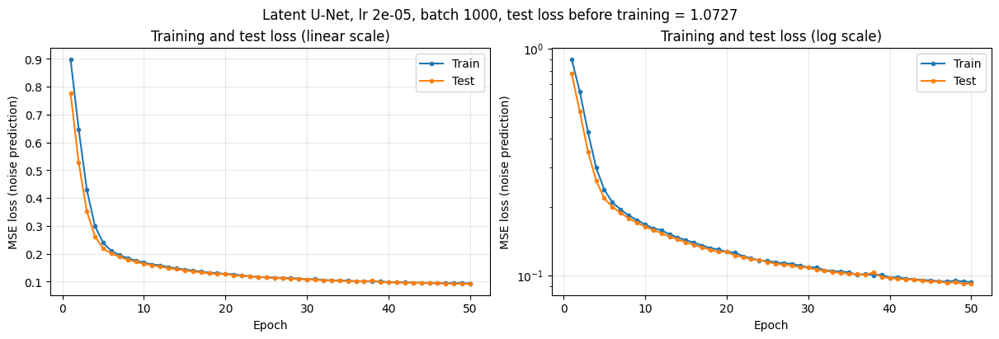

In [26]:
epochs_axis = np.arange(1, len(training_losses) + 1)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, scale in zip(axes, ["linear", "log"]):
    ax.plot(epochs_axis, training_losses, marker="o", markersize=3, label="Train")
    ax.plot(epochs_axis, testing_losses, marker="o", markersize=3, label="Test")
    ax.set_xlabel("Epoch")
    ax.set_ylabel("MSE loss (noise prediction)")
    ax.set_yscale(scale)
    ax.set_title(f"Training and test loss ({scale} scale)")
    ax.grid(alpha=0.3)
    ax.legend()
fig.suptitle(f"Latent U-Net, lr {LR}, batch {BATCH_SIZE}, test loss before training = {initial_test_loss:.4f}")
plt.savefig("figures/loss_curves.png", dpi=120)
plt.show()

> **Observation:** The loss drops quickly at first, from 1.0727 before training to a test loss of 0.2188 by epoch 5, and then slowly. It is still going down at epoch 50: the test loss went from 0.0974 at epoch 40 to 0.0918 at epoch 50, about 0.0005 per epoch, so the model hasn't converged. Train and test stay almost on top of each other (final 0.0935 and 0.0918), so there is no sign of overfitting. Test is usually a little lower because the train number is averaged while the weights are still improving during the epoch. There are two small bumps in the test loss, at epochs 20 and 38.

## 17. Classifier-Free Guidance Sampling (Assignment Part 5)

Sampling is the demo's DDPM reverse loop, run in latent space. It starts from pure noise z_T ~ N(0, I) of shape [64, 4, 32, 32] and goes from t = 1000 down to t = 1. At each step the model is called twice, once with the class label and once with the null label, and the two predictions are combined:

$$\hat\epsilon = (1 + w)\,\epsilon_\theta(z_t, t, y) - w\,\epsilon_\theta(z_t, t, \varnothing), \qquad w = 3.$$

The conditional and unconditional calls are done as one batch of 128 to save time (the result is the same as two separate calls). Then, like the demo:

$$z_{t-1} = \frac{1}{\sqrt{\alpha_t}}\Big(z_t - \frac{\beta_t}{\sqrt{1-\bar\alpha_t}}\hat\epsilon\Big) + \sigma_t\, n, \qquad \sigma_t^2 = \beta_t\frac{1-\bar\alpha_{t-1}}{1-\bar\alpha_t},$$

with no noise added at the last step. Only the final z_0 (and a few intermediate latents) go through `vae.decode(z / 0.18215)`.

Intuition for the guidance: ε_cond − ε_uncond is the part of the prediction that comes from knowing the class. Multiplying it by (1 + w) pushes the sample further in the direction of "looks like this class", which usually makes samples more clearly class-specific but less varied. w = 0 is plain conditional sampling.

The labels are 0-9 repeated (sample i gets label i mod 10), so 64 images cover every class 6 or 7 times.

In [27]:
@torch.no_grad()
def sample_cfg(labels, w, z_T, noise_seed, keep=0):
    # reverse diffusion in latent space with classifier-free guidance; returns z_0 and kept intermediates
    model.eval()
    n = len(labels)
    z = z_T.clone().to(device)
    null = torch.full_like(labels, NULL_LABEL)
    gen = make_generator(noise_seed)
    intermediates = [(T, z[:keep].cpu())] if keep else []

    for timestep in reversed(range(T)):
        t = torch.full((n,), timestep, device=device, dtype=torch.long)
        with autocast():
            if w == 0:
                predicted_noise = model(z, t, labels).float()
            else:
                eps = model(torch.cat([z, z]), torch.cat([t, t]), torch.cat([labels, null])).float()
                eps_cond, eps_uncond = eps.chunk(2)
                predicted_noise = (1 + w) * eps_cond - w * eps_uncond

        mean = (1 / torch.sqrt(alphas[timestep])) * (
            z - ((1 - alphas[timestep]) / sqrt_one_minus_alpha_bars[timestep]) * predicted_noise
        )
        if timestep > 0:
            z = mean + posterior_sigma[timestep] * randn(z.shape, gen)
        else:
            z = mean

        # after this step z is z_{timestep} in 1-based terms (timestep 0 = final sample)
        if keep and timestep % SAVE_EVERY == 0:
            intermediates.append((timestep, z[:keep].cpu()))
    return z, intermediates


sample_labels = (torch.arange(N_SAMPLES) % NUM_CLASSES).to(device)
z_T = torch.randn((N_SAMPLES, *LATENT_SHAPE), generator=make_generator(SEED))

sync()
t0 = time.time()
z0_w3, intermediates = sample_cfg(sample_labels, GUIDANCE_W, z_T, noise_seed=SEED + 2, keep=NUM_CLASSES)
sync()
sample_time_w3 = time.time() - t0
images_w3 = decode_in_batches(z0_w3).clamp(-1, 1)
log(f"CFG sampling w={GUIDANCE_W}: {N_SAMPLES} samples x {T} steps in {sample_time_w3:.1f}s | "
    f"z_0 mean {z0_w3.mean().item():.4f}, std {z0_w3.std().item():.4f} | decoded {tuple(images_w3.shape)}")
assert z0_w3.shape == (N_SAMPLES, *LATENT_SHAPE) and torch.isfinite(z0_w3).all()
if z0_w3.std().item() > 5 * latent_stats["train_scaled_std"]:
    log("WARNING: generated latents are much larger than real latents, the decoded images will not look right "
        "(expected in the smoke test, where the model is untrained)")

[2026-11-03T22:21:18Z] CFG sampling w=3: 64 samples x 1000 steps in 51.0s | z_0 mean -0.3383, std 1.8371 | decoded (64, 3, 256, 256)


## 18. Generated Image Grids

The main 64-image grid (8 × 8). Each image is titled with the class it was asked to generate.

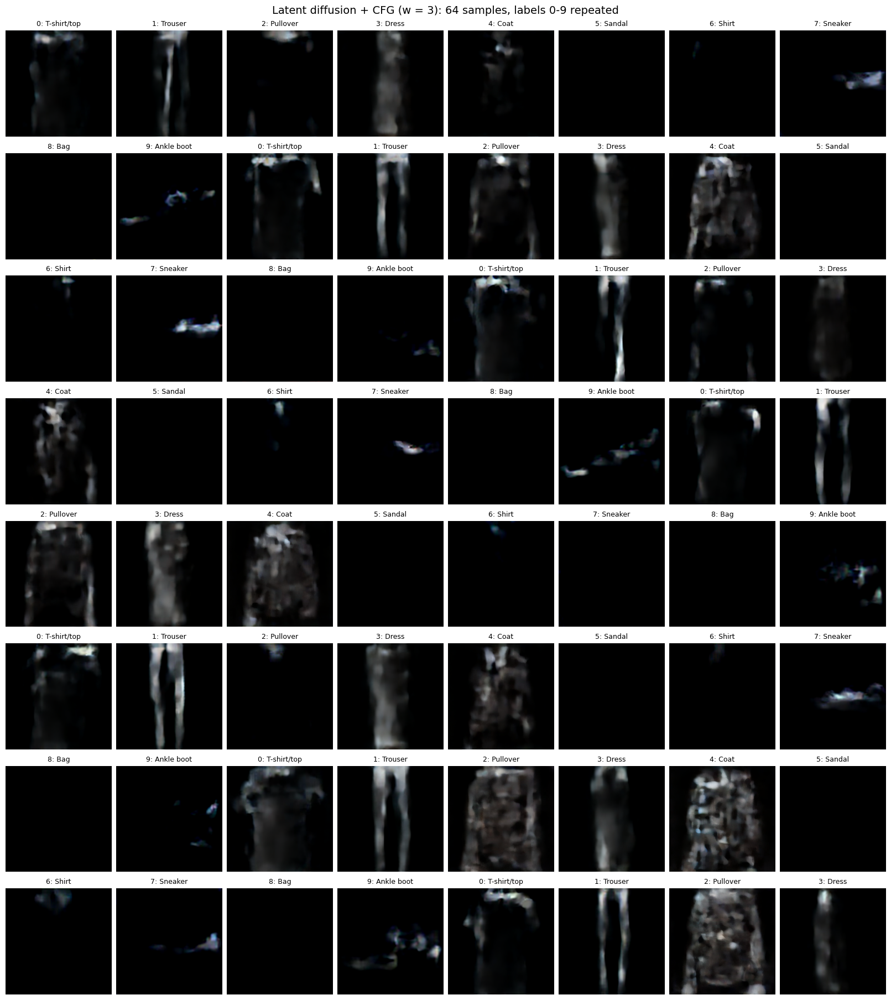

In [28]:
def plot_sample_grid(images, labels, title, path, ncol=8):
    nrow = math.ceil(len(images) / ncol)
    fig, axes = plt.subplots(nrow, ncol, figsize=(2 * ncol, 2.25 * nrow), squeeze=False)
    for k, ax in enumerate(axes.flat):
        ax.axis("off")
        if k < len(images):
            ax.imshow(denorm(images[k]).permute(1, 2, 0).numpy())
            ax.set_title(f"{int(labels[k])}: {class_names[int(labels[k])]}", fontsize=9)
    fig.suptitle(title, fontsize=14)
    plt.savefig(path, dpi=110)
    plt.show()


plot_sample_grid(images_w3, sample_labels.cpu(), f"Latent diffusion + CFG (w = {GUIDANCE_W}): {N_SAMPLES} samples, labels 0-9 repeated",
                 "figures/cfg_samples_w3.png")

The reverse process for one sample of each class (the first 10 samples), decoded with the VAE at t = 1000, 800, 600, 400, 200, and 0. This is the demo's "Conditional DDPM Generation" figure, but every column is a VAE decode of the latent at that step.

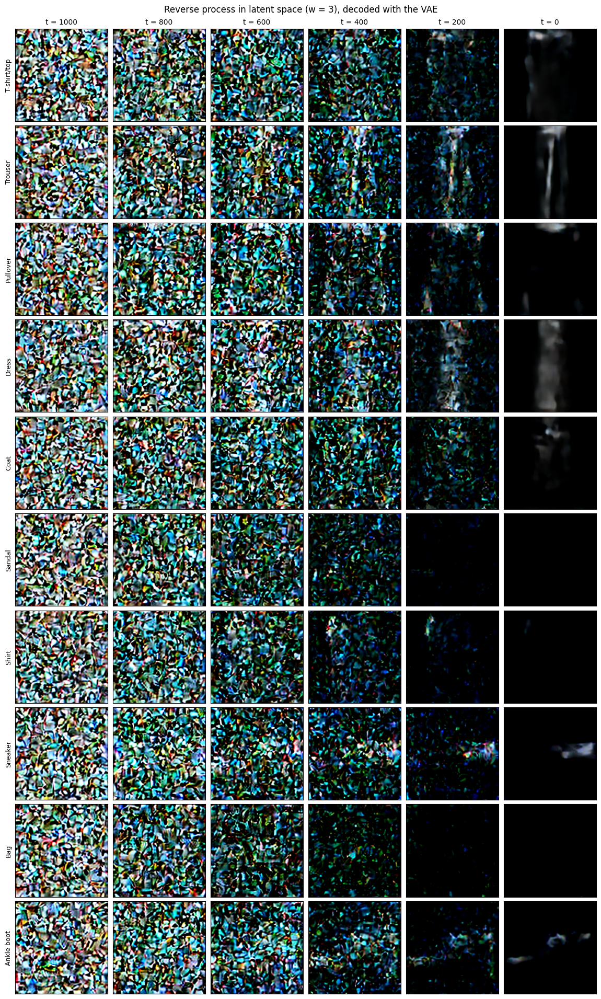

In [29]:
steps = [s for s, _ in intermediates]
decoded_steps = [decode_in_batches(z).clamp(-1, 1) for _, z in intermediates]
fig, axes = plt.subplots(NUM_CLASSES, len(steps), figsize=(1.9 * len(steps), 1.9 * NUM_CLASSES))
for col, (step, imgs) in enumerate(zip(steps, decoded_steps)):
    for row in range(NUM_CLASSES):
        ax = axes[row, col]
        ax.imshow(denorm(imgs[row]).permute(1, 2, 0).numpy())
        ax.set_xticks([])
        ax.set_yticks([])
        if col == 0:
            ax.set_ylabel(class_names[row], fontsize=9)
        if row == 0:
            ax.set_title(f"t = {step}", fontsize=10)
fig.suptitle(f"Reverse process in latent space (w = {GUIDANCE_W}), decoded with the VAE")
plt.savefig("figures/cfg_denoising_steps.png", dpi=110)
plt.show()

### Effect of guidance: w = 0 vs. w = 3

To see what the guidance actually does, I run the sampler again with w = 0 (only the conditional prediction) from **the same z_T and the same per-step noise**. Any difference between the two grids comes only from the guidance term. Two samples per class are shown.

[2026-11-03T22:22:11Z] sampling w=0: 27.9s | z_0 mean -0.2664, std 1.6943


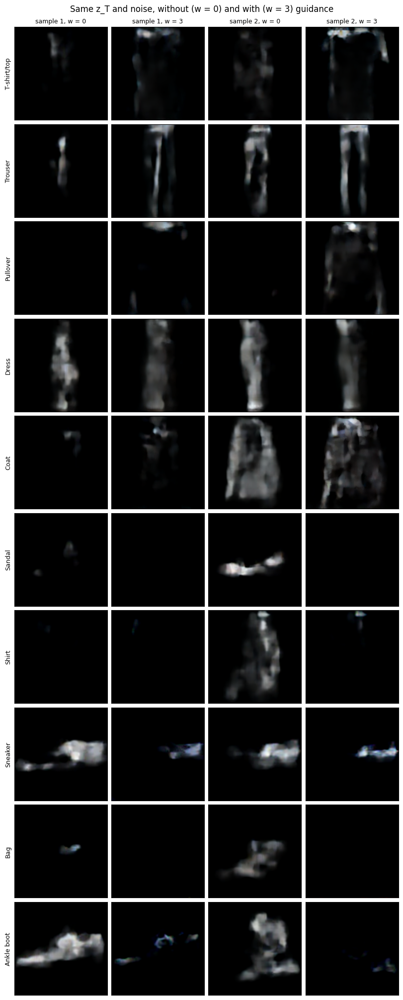

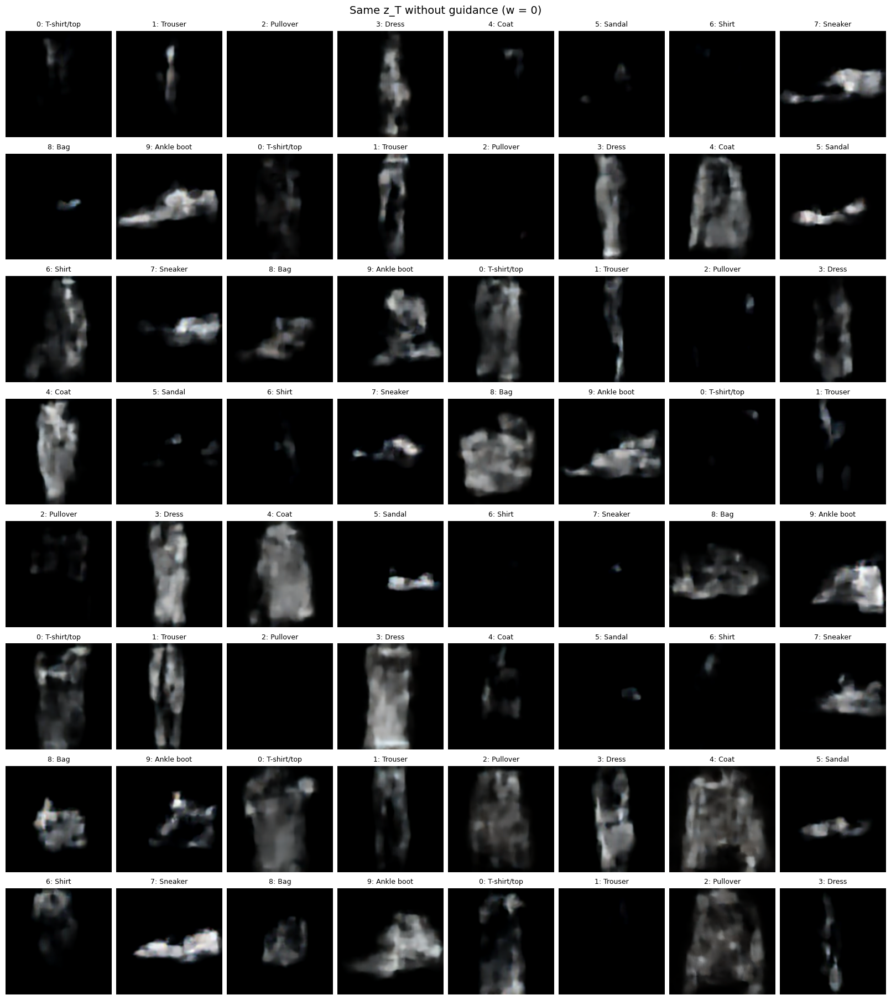

In [30]:
sync()
t0 = time.time()
z0_w0, _ = sample_cfg(sample_labels, 0, z_T, noise_seed=SEED + 2)
sync()
sample_time_w0 = time.time() - t0
images_w0 = decode_in_batches(z0_w0).clamp(-1, 1)
log(f"sampling w=0: {sample_time_w0:.1f}s | z_0 mean {z0_w0.mean().item():.4f}, std {z0_w0.std().item():.4f}")

n_show = min(2 * NUM_CLASSES, N_SAMPLES)
fig, axes = plt.subplots(NUM_CLASSES, 4, figsize=(8, 2 * NUM_CLASSES), squeeze=False)
for k in range(n_show):
    row, rep = k % NUM_CLASSES, k // NUM_CLASSES
    for j, (imgs, w) in enumerate([(images_w0, 0), (images_w3, GUIDANCE_W)]):
        ax = axes[row, 2 * rep + j]
        ax.imshow(denorm(imgs[k]).permute(1, 2, 0).numpy())
        ax.set_xticks([])
        ax.set_yticks([])
        if row == 0:
            ax.set_title(f"sample {rep + 1}, w = {w}", fontsize=9)
        if 2 * rep + j == 0:
            ax.set_ylabel(class_names[row], fontsize=9)
for k in range(n_show, 2 * NUM_CLASSES):   # only happens in the smoke test (fewer than 20 samples)
    for j in range(2):
        axes[k % NUM_CLASSES, 2 * (k // NUM_CLASSES) + j].set_visible(False)
fig.suptitle("Same z_T and noise, without (w = 0) and with (w = 3) guidance")
plt.savefig("figures/cfg_w0_vs_w3.png", dpi=110)
plt.show()

plot_sample_grid(images_w0, sample_labels.cpu(), f"Same z_T without guidance (w = 0)", "figures/cfg_samples_w0.png")

### Checking the class labels with a small latent classifier

Looking at the grids is the main check, but to put a number on "does the image match the requested class" I train a tiny CNN classifier on the cached **real** training latents (two strided convs and a linear layer, a few epochs) and then ask it which class each generated latent belongs to. This classifier is only an evaluation tool. It is not part of the diffusion model, and its accuracy on real test latents is printed so we know how much to trust it. Generated latents can look different from real ones, so this agreement number is a rough check, not a real quality metric like FID.

In [31]:
set_seed(SEED)
latent_clf = nn.Sequential(
    nn.Conv2d(4, 32, 3, stride=2, padding=1), nn.ReLU(),
    nn.Conv2d(32, 64, 3, stride=2, padding=1), nn.ReLU(),
    nn.AdaptiveAvgPool2d(1), nn.Flatten(), nn.Linear(64, NUM_CLASSES),
).to(device)
clf_opt = optim.Adam(latent_clf.parameters(), lr=1e-3)
g_clf = make_generator(SEED + 3)
for ep in range(CLF_EPOCHS):
    latent_clf.train()
    perm = torch.randperm(len(train_ids), generator=g_clf).to(device)
    for b in range(0, len(perm), 256):
        ids = perm[b:b + 256]
        loss = F.cross_entropy(latent_clf(sample_z0(train_mean, train_std, ids, g_clf)), train_y[ids])
        clf_opt.zero_grad()
        loss.backward()
        clf_opt.step()


@torch.no_grad()
def classify(z):
    latent_clf.eval()
    return torch.cat([latent_clf(z[i:i + 1000].to(device)).argmax(1) for i in range(0, len(z), 1000)])


clf_test_acc = (classify(test_mean.float() * LATENT_SCALE) == test_y).float().mean().item()
pred_w3 = classify(z0_w3)
pred_w0 = classify(z0_w0)
agree_w3 = (pred_w3 == sample_labels).float().mean().item()
agree_w0 = (pred_w0 == sample_labels).float().mean().item()
log(f"latent classifier test accuracy on real latents: {clf_test_acc:.4f}")
log(f"generated samples classified as the requested class: w={GUIDANCE_W}: {agree_w3:.3f} | w=0: {agree_w0:.3f}")
per_class_agree = {class_names[c]: (pred_w3[sample_labels == c] == c).float().mean().item() for c in range(NUM_CLASSES)}
print(f"{'class':<12} {'agreement w=' + str(GUIDANCE_W):>16}")
for name, v in per_class_agree.items():
    print(f"{name:<12} {v:>16.2f}")

[2026-11-03T22:22:28Z] latent classifier test accuracy on real latents: 0.7097
[2026-11-03T22:22:28Z] generated samples classified as the requested class: w=3: 0.203 | w=0: 0.188
class           agreement w=3
T-shirt/top              0.00
Trouser                  0.43
Pullover                 0.00
Dress                    0.57
Coat                     0.00
Sandal                   0.00
Shirt                    0.00
Sneaker                  1.00
Bag                      0.00
Ankle boot               0.00


### One-step denoising of real test latents (like Demo 3)

The Stable Diffusion demo ends with an original / noisy decode / denoised decode comparison. I repeat that with the trained U-Net. Four test latents are noised to t = 200 and t = 500, the model predicts ε (with the true label), and the clean latent is estimated in a single step from the forward formula:

$$\hat z_0 = \frac{z_t - \sqrt{1-\bar\alpha_t}\,\hat\epsilon}{\sqrt{\bar\alpha_t}}.$$

Unlike the demo's tiny CNN, the model predicts the noise, not the clean latent, so ẑ_0 comes from rearranging the forward formula.

[2026-11-03T22:22:30Z] one-step denoising latent MSE vs clean z_0: t=200: noisy 0.3943 -> denoised 0.0682, t=500: noisy 1.7935 -> denoised 0.2718


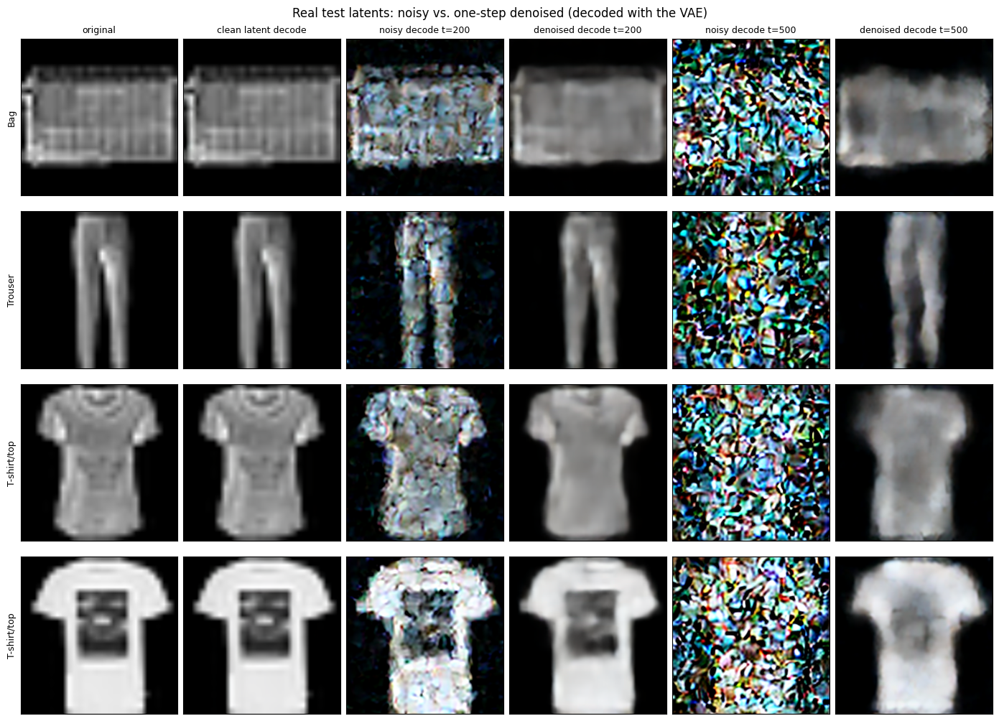

In [32]:
den_ids = torch.arange(0, 4, device=device) + min(SLICE, len(test_ids) - 4)
g_den = make_generator(SEED + 4)
z0_den = sample_z0(test_mean, test_std, den_ids, g_den)
rows = [("original", preprocess(test_set.data[test_ids[den_ids.cpu()]]).cpu()), ("clean latent decode", decode_in_batches(z0_den))]
latent_mse_den = {}
for t in [200, 500]:
    idx = torch.full((len(den_ids),), t - 1, device=device, dtype=torch.long)
    z_t, eps = q_sample(z0_den, idx, randn(z0_den.shape, g_den))
    with torch.no_grad(), autocast():
        eps_hat = model(z_t, idx, test_y[den_ids]).float()
    z0_hat = (z_t - sqrt_one_minus_alpha_bars[t - 1] * eps_hat) / sqrt_alpha_bars[t - 1]
    latent_mse_den[t] = {"noisy": F.mse_loss(z_t, z0_den).item(), "denoised": F.mse_loss(z0_hat, z0_den).item()}
    rows += [(f"noisy decode t={t}", decode_in_batches(z_t)), (f"denoised decode t={t}", decode_in_batches(z0_hat))]
log("one-step denoising latent MSE vs clean z_0: " + ", ".join(
    f"t={t}: noisy {v['noisy']:.4f} -> denoised {v['denoised']:.4f}" for t, v in latent_mse_den.items()))

fig, axes = plt.subplots(len(den_ids), len(rows), figsize=(2.3 * len(rows), 2.5 * len(den_ids)))
for i in range(len(den_ids)):
    for j, (name, imgs) in enumerate(rows):
        axes[i, j].imshow(denorm(imgs[i]).permute(1, 2, 0).numpy())
        axes[i, j].set_xticks([])
        axes[i, j].set_yticks([])
        if i == 0:
            axes[i, j].set_title(name, fontsize=9)
    axes[i, 0].set_ylabel(class_names[int(test_y[den_ids[i]])], fontsize=9)
fig.suptitle("Real test latents: noisy vs. one-step denoised (decoded with the VAE)")
plt.savefig("figures/one_step_denoising.png", dpi=110)
plt.show()

### Saving the metrics and the final model

Everything reported in METRICS.md comes from `results/hw9_metrics.json`. The final U-Net weights go to `checkpoints/ldm_unet_seed_9486.pt`.

In [33]:
metrics = {
    "config": CONFIG,
    "personal_parameters": {"SID4": SID4, "SEED": SEED, "SLICE": SLICE, "HP_ID": HP_ID, "CLS_A": CLS_A, "CLS_B": CLS_B},
    "environment": {"device": device, "device_name": device_name, "mixed_precision": USE_AMP, "micro_batch": MICRO_BATCH,
                    "torch": torch.__version__, "torchvision": torchvision.__version__, "diffusers": diffusers.__version__},
    "shapes": {"image": [3, IMG_SIZE, IMG_SIZE], "latent": list(LATENT_SHAPE),
               "attention_inputs": {k: list(v) for k, v in attn_sizes.items()}},
    "vae_parameters": vae_params,
    "unet_parameters": n_params,
    "reconstruction": recon_mse,
    "latent_stats": latent_stats,
    "schedule_alpha_bar": schedule_table,
    "forward_decoded_mse_vs_clean": decoded_mse,
    "forward_image_index": viz_idx,
    "initial_test_loss": initial_test_loss,
    "training_losses": training_losses,
    "testing_losses": testing_losses,
    "final_test": final_test,
    "epoch_times_s": epoch_times,
    "train_time_s": train_time,
    "latent_cache_time_s": cache_time,
    "sampling": {"time_w3_s": sample_time_w3, "time_w0_s": sample_time_w0,
                 "z0_std_w3": z0_w3.std().item(), "z0_std_w0": z0_w0.std().item()},
    "label_check": {"classifier_test_accuracy": clf_test_acc, "agreement_w3": agree_w3, "agreement_w0": agree_w0,
                    "per_class_agreement_w3": per_class_agree},
    "one_step_denoising_latent_mse": latent_mse_den,
}
with open("results/hw9_metrics.json", "w") as f:
    json.dump(metrics, f, indent=2)
FINAL_CKPT = f"checkpoints/ldm_unet_seed_{SEED}.pt"
torch.save({"config": CONFIG, "model": model.state_dict()}, FINAL_CKPT)
log("saved results/hw9_metrics.json and", FINAL_CKPT)

[2026-11-03T22:22:32Z] saved results/hw9_metrics.json and checkpoints/ldm_unet_seed_9486.pt


## 19. Analysis and Discussion

**VAE.** The VAE part worked well. The reconstruction MSE is 0.00013 on [-1, 1] and the reconstructions look the same as the originals, with only faint errors around edges. Each image goes from 196,608 numbers to 4,096 (48 times fewer), so working in latent space costs very little quality on this data. The latents aren't unit variance though. After scaling by 0.18215 the training latents have std 1.37, not 1.

**Forward diffusion.** The decoded images follow the schedule: recognizable at t = 200, gone by t = 500, and nearly the same at t = 800 and t = 1000 (ᾱ_1000 is about 0.00004). Noise looks different in the two spaces. On pixels it's static, and through the VAE decoder it turns into colored blobs.

**Training.** The final test noise-prediction MSE is 0.0918, down from 1.0727 before training. The model does learn to predict the noise, but the loss is still falling at epoch 50. The conditional test loss (0.0915) is only about 2% lower than the unconditional one (0.0934), so at the end of training the label isn't helping the noise prediction very much.

**One-step denoising.** On real test latents the model does a reasonable job in a single step. The latent MSE against the clean latent goes from 0.394 to 0.068 at t = 200, and from 1.793 to 0.272 at t = 500. The denoised decodes are blurry, but the clothing is clearly recognizable.

**Sampling.** This is the weak part of my results, and the 64-image grid is not good:

- With w = 3, Trouser and Dress are the most recognizable. T-shirt, Pullover, and Coat give a rough torso shape, often with dark patches. Sneaker is usually a small streak on the right side, and Ankle boot is scattered pieces.
- All six Sandal and all six Bag panels are basically black, and Shirt is only a small spot near the top.
- The denoising figure shows that shapes only start to appear around t = 400 to 200, and the panels that end up black are already fading by then.

**w = 0 vs. w = 3.** Starting from the same z_T and noise, guidance doesn't simply make everything better. Trouser, T-shirt, and Pullover get clearer outlines at w = 3 (Pullover is often empty at w = 0). Sandal and Bag go the other way: they show blobs at w = 0 and disappear at w = 3. The images also pick up some color tints at w = 3, even though the data is grayscale.

**Label check.** The latent classifier agrees with the requested label for 20.3% of samples at w = 3 (13 of 64) and 18.8% at w = 0 (12 of 64). That is above the 10% you would get by chance, but one sample is not a real difference between the two. By class at w = 3, it is 100% for Sneaker, 57% for Dress, 43% for Trouser, and 0% for the rest. I don't fully trust this number, since the classifier only reaches 71.0% on real test latents and there are only 6 or 7 samples per class, but it does agree with what I see in the grid.

**Why the samples are weak.** I didn't test this directly, so this is my best explanation. Batch 1000 means only 3,000 optimizer steps at lr 2e-5, and the loss was still falling, so I think the model is underfit. It's good enough for one-step denoising, but sampling chains 1,000 of these predictions and the errors can build up. The generated latents do end up off from the real ones: std 1.84 at w = 3 and 1.69 at w = 0 vs. 1.37 for real latents, and mean -0.34 and -0.27 vs. -0.01. Guidance then multiplies the difference between the conditional and unconditional predictions by 4 and 3, so it can push an imperfect model further off, which may be what happens to Sandal and Bag. A smaller batch would give many more updates at the same learning rate, but I didn't run that, so I can't say how much it would help.

## 20. Limitations

- **Sample quality.** The model is underfit and the generated images are weak (Section 19). Three classes come out almost empty at w = 3, so this run shows that the pipeline works from end to end but doesn't produce good class-conditional images.
- **Domain mismatch for the VAE.** `sd-vae-ft-mse` was trained on natural RGB photos, while FashionMNIST is gray, 28×28, and upscaled 9 times to 256×256. The VAE works on it, but the 0.18215 scaling was chosen for that other data. Here the scaled training latents have std 1.37 instead of about 1.
- **Upscaling costs compute without adding detail.** The images only have 28×28 real pixels. I resized to 256×256 so that the latent is 32×32 and attention can happen at 16×16 as required; with 64×64 images (as in the demo) the latent would be 8×8 and that resolution wouldn't exist in the U-Net.
- **Short training at a small learning rate.** lr 2e-5 for 50 epochs is fixed by the assignment. The batch size of 1000 came from the demo, and it gives only 3,000 optimizer steps. I didn't tune any of these.
- **No standard quality metric.** I didn't compute FID. The label-agreement check uses a small classifier that reaches only 71.0% on real test latents, and it only sees 64 generated samples, so it's a rough check.
- **One run, one seed.** All results come from a single training run with SEED = 9486.
- **Determinism.** Some CUDA kernels used here (for example the bilinear upsampling backward pass) are not deterministic, and mixed precision on the T4 gives slightly different numbers than fp32 on a Mac, so a rerun on a different device can differ in the last digits.
- **No backup on Kaggle.** The Drive backup only works on Colab, so the final run had to finish in one session. It did, in about 2 hours 5 minutes, which is slightly over the 2 hours I was aiming for.

## 21. Conclusion

I built a class-conditional latent diffusion model on FashionMNIST using the pretrained `sd-vae-ft-mse` VAE, a U-Net with self-attention at 16×16 and in the bottleneck, and classifier-free guidance with w = 3, and trained it for the full 50 epochs on a Kaggle T4. The VAE reconstructs the images almost perfectly (MSE 0.00013), and the U-Net reached a test noise-prediction MSE of 0.0918 and can denoise real latents reasonably well in one step.

The generated images are the weak part. Trouser and Dress are recognizable at w = 3, but Sandal and Bag come out black, and only 20.3% of samples match their label according to the rough classifier check. Guidance sharpened some classes and wiped out others instead of improving all of them. The main thing I took from this is that a low noise-prediction loss doesn't guarantee good samples. The test loss looks fine and one-step denoising works, but full sampling needs a much better model. Since the loss was still falling, the first thing I'd try next is more optimizer steps, for example with a smaller batch.

## 22. AI Use

How I used AI tools for this assignment is described in `AI_USE.md` in this folder.

## Download the Outputs

This cell zips `figures/`, `results/`, and the final model weights into `HW9_outputs.zip` (the latent cache, the data, and the resume checkpoint are left out because they are large and can be rebuilt). On Colab it also tries to save a copy of this notebook with its outputs into the zip, and then starts the download. If the notebook copy fails, use File → Download → Download .ipynb.

In [34]:
ZIP_PATH = "HW9_outputs.zip"
in_colab = IN_COLAB

notebook_copy = None
if in_colab:
    try:
        from google.colab import _message
        nb = _message.blocking_request("get_ipynb", request="", timeout_sec=60)["ipynb"]
        notebook_copy = "HW9_Latent_Diffusion_CFG_executed.ipynb"
        with open(notebook_copy, "w") as f:
            json.dump(nb, f)
    except Exception as e:
        print("could not save a copy of the notebook:", e)
        notebook_copy = None

with zipfile.ZipFile(ZIP_PATH, "w", zipfile.ZIP_DEFLATED) as zf:
    for folder in ["figures", "results"]:
        for root, _, files in os.walk(folder):
            for name in sorted(files):
                zf.write(os.path.join(root, name))
    if os.path.exists(FINAL_CKPT):
        zf.write(FINAL_CKPT)
    if notebook_copy:
        zf.write(notebook_copy)
    names = zf.namelist()
log(f"wrote {ZIP_PATH} ({os.path.getsize(ZIP_PATH) / 1e6:.1f} MB, {len(names)} files)")
print("\n".join(names))

if in_colab:
    from google.colab import files
    files.download(ZIP_PATH)

[2026-11-03T22:22:34Z] wrote HW9_outputs.zip (35.7 MB, 14 files)
figures/beta_schedule.png
figures/cfg_denoising_steps.png
figures/cfg_samples_w0.png
figures/cfg_samples_w3.png
figures/cfg_w0_vs_w3.png
figures/fashionmnist_examples.png
figures/forward_diffusion_latent.png
figures/latent_channels.png
figures/loss_curves.png
figures/one_step_denoising.png
figures/vae_reconstructions.png
results/hw9_metrics.json
results/run_log_raw.txt
checkpoints/ldm_unet_seed_9486.pt
